In [1]:
import os
import re
import sys
import glob
import time
import uproot
import ternary
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime

from scipy.signal import savgol_filter

from functools import partial

from matplotlib.colors import LogNorm

from collections import Counter

from scipy.optimize import curve_fit

In [2]:
### Import functions from peak_functions

repository_path = os.path.abspath('/Users/romoluque_c/Repositories/BACoN_romo/')
sys.path.append(repository_path)

import blr_functions  as blr
import peak_functions as pf
import fit_functions  as fitf

In [3]:
import matplotlib

# Set Palatino as the serif font
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif']  = 'Palatino'

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
plt.rcParams["figure.figsize"] = 8, 5
plt.rcParams["font.size"]      = 14

In [6]:
fav_col = '#418094'

## Analyze npz data

In [9]:
def extract_date_obj_and_number(filename):
    match       = re.search(r"(\d{2}_\d{2}_\d{4})-file_(\d+)", filename)
    date_str    = match.group(1)
    file_number = int(match.group(2))
    date_obj    = datetime.strptime(date_str, "%m_%d_%Y")
    return date_obj, file_number

def extract_date_and_number(filename):
    match = re.search(r"(\d{2}_\d{2}_\d{4})-file_(\d+)", filename)
    return match.group(1), int(match.group(2))

def adapt_evt_id(evt_id, fnum):
    return 1000000*fnum + np.array(evt_id)

thr_ADC        = 90
sg_filt_window = 30
min_dist       = 25

normal_chs  = range(9)
trigger_chs = [9, 10, 11]
pmt_ch      = 12

evts_path      = '/Users/romoluque_c/LEGEND/BACON/new_setup_run6/data_npz/'
evts_path_cuts = '/Users/romoluque_c/LEGEND/BACON/new_setup_run6/data_npz_cuts/'
filt_files     = glob.glob(evts_path + f'/BACoN_run6_hits_and_times_newint_thr{thr_ADC}_mean_w{sg_filt_window}_dist{min_dist}_run*.npz')
sorted_files   = sorted(filt_files, key=extract_date_obj_and_number)
len(sorted_files)

941

In [10]:
def expected_pmt_file(evts_path, date, fnum):
    return f"{evts_path}/BACoN_pmt_analysis_peaks_thr60_dist15_run-{date}-file_{fnum}.npz"

def filename_cut(evts_path_cuts, text, date, fnum):
    return f"{evts_path_cuts}/BACoN_{text}_run-{date}-file_{fnum}.npz"

In [11]:
import json

with open("/Users/romoluque_c/Repositories/BACON_romo/example_notebooks/Run6/SiPM_calibration_trigg_using_height.json", "r") as f:
    cal_h_trigg = json.load(f)
with open("/Users/romoluque_c/Repositories/BACON_romo/example_notebooks/Run6/SiPM_calibration_using_height.json", "r") as f:
    cal_h_non_trigg = json.load(f)

## Combine the following cuts:
### - Remove PMT saturating events
### - Use % charge with ternary plot
### - Remove events with hits before thr trigger time

In [217]:
def filter_events_by_trigger_window(idcs_trigg, hs_trigg, ev_set):
    
    selected_evts = set()
    sel_chs = [9, 10, 11]

    for ev in ev_set:

        pass_condition = False

        for ch in sel_chs:
            t = idcs_trigg[ch][ev]
            h = hs_trigg  [ch][ev]

            if not isinstance(h, np.ndarray):
                t = np.array([t])
                h = np.array([h])

            # convert to PE
            a, b = cal_h_trigg[date][str(ch)]
            h_pe = (h - b) / a

            mask = (t > 1400) & (t < 1700)
            pe_sum = np.sum(h_pe[mask]) if mask.any() else 0

            if not (0.5 <= pe_sum <= 1.5):
                pass_condition = True

        if pass_condition:
            selected_evts.add(ev)

    return selected_evts

In [218]:
from functools import reduce

def get_events_passing_all_cuts(events_cut1, events_cut2, events_cut3):
    
    c1 = set(events_cut1)
    c2 = set(events_cut2)
    c3 = set(events_cut3)
        
    remaining      = c1 - c2 #remove saturating events PMT
    events_passing = remaining & c3
    
    return sorted(list(events_passing))

def process_file(sipm_file, apply_thr=False, trigg_cut=False):

    date, fnum = extract_date_and_number(sipm_file)

    pmt_file = expected_pmt_file(evts_path,              date, fnum)
    cutfile2 = filename_cut(evts_path_cuts, 'filt_cut2', date, fnum)
    cutfile3 = filename_cut(evts_path_cuts, 'filt_cut3', date, fnum)
    cutfile5 = filename_cut(evts_path_cuts, 'filt_cut5', date, fnum)

    if not os.path.exists(pmt_file):
        print(f"Skipping: missing PMT file for {date} {fnum}")
        return

    sipm_data = np.load(sipm_file, allow_pickle=True)
    pmt_data  = np.load(pmt_file,  allow_pickle=True)
    cut2_data = np.load(cutfile2,  allow_pickle=True)
    cut3_data = np.load(cutfile3,  allow_pickle=True)
    cut5_data = np.load(cutfile5,  allow_pickle=True)

    d_filt_evts = sipm_data['filt_evts_dict'] .item()
    d_idx_max   = sipm_data['idx_peaks_max']  .item()
    d_height_sg = sipm_data['height_peaks_sg'].item()
        
    if apply_thr:
        #### Apply second threshold to clean and get rid of additional peaks in the t dist after the singlet
        d_filt_evts, d_idx_max, d_height_sg = apply_thr_to_height_and_indcs(thr_chs, d_filt_evts, d_idx_max, d_height_sg)
    
    d_idx_max_trigg   = sipm_data['idx_peaks_max_trigg']  .item()
    d_height_sg_trigg = sipm_data['height_peaks_sg_trigg'].item()
    d_idx_pmt         = pmt_data ['idx_peaks_pmt']
  
    sat_evts_pmt = cut2_data['sat_evts_pmt']
  
    pe_10_75     = cut3_data['sum_h_PE_indcs_10_75']
    pe_25_50     = cut3_data['sum_h_PE_indcs_25_50']
    
    ## For the pretrigger cut we should only use the trigger SiPMs
    f_evt_trigg_cut5 = cut5_data['f_evts_trigg'].item()
    common_evts_cut5 = reduce(np.intersect1d, [f_evt_trigg_cut5[ch] for ch in trigger_chs])
    
    ev1 = set(get_events_passing_all_cuts(common_evts_cut5, sat_evts_pmt, pe_10_75))
    ev2 = set(get_events_passing_all_cuts(common_evts_cut5, sat_evts_pmt, pe_25_50))
    
    if trigg_cut:
        ev1 = filter_events_by_trigger_window(d_idx_max_trigg, d_height_sg_trigg, ev1)
        ev2 = filter_events_by_trigger_window(d_idx_max_trigg, d_height_sg_trigg, ev2)
  
    idx1, idx2 = {}, {}
    nPE1, nPE2 = {}, {}
  
    for ch in normal_chs:
        evts  = d_filt_evts[ch]
        idx   = d_idx_max  [ch]
        h_ADC = d_height_sg[ch]
  
        mask1 = [e in ev1 for e in evts]
        mask2 = [e in ev2 for e in evts]
  
        idx1[ch] = idx[mask1]
        idx2[ch] = idx[mask2]
        
        nPE1[ch] = (h_ADC[mask1] - cal_h_non_trigg[str(ch)][1])/cal_h_non_trigg[str(ch)][0]
        nPE2[ch] = (h_ADC[mask2] - cal_h_non_trigg[str(ch)][1])/cal_h_non_trigg[str(ch)][0]
  
    for ch in trigger_chs:
        idx   = d_idx_max_trigg[ch]
        evts  = range(len(idx))  # implicit event numbering
        h_ADC = d_height_sg_trigg[ch]
  
        mask1 = [e in ev1 for e in evts]
        mask2 = [e in ev2 for e in evts]
  
        idx1[ch] = idx[mask1]
        idx2[ch] = idx[mask2]
        
        nPE1[ch] = (h_ADC[mask1] - cal_h_trigg[date][str(ch)][1])/cal_h_trigg[date][str(ch)][0]
        nPE2[ch] = (h_ADC[mask2] - cal_h_trigg[date][str(ch)][1])/cal_h_trigg[date][str(ch)][0]
  
    pmt_ch = 12
    evts   = range(len(d_idx_pmt))
  
    mask1 = [e in ev1 for e in evts]
    mask2 = [e in ev2 for e in evts]
  
    idx1[pmt_ch] = d_idx_pmt[mask1]
    idx2[pmt_ch] = d_idx_pmt[mask2]
    
    #nPE1[pmt_ch] = np.array([])
    #nPE2[pmt_ch] = np.array([])
    
    return idx1, idx2, nPE1, nPE2


def is_non_empty(data):
    if data is None:
        return False
    if isinstance(data, np.ndarray):
        return data.size > 0
    if isinstance(data, list):
        return len(data) > 0 and any((arr.size > 0 if isinstance(arr, np.ndarray) else len(arr) > 0)
                                     for arr in data)
    return False

In [96]:
all_chs = range(13)

all_params = ['idx_max_cuts1',
              'idx_max_cuts2',
              'height_sg_cuts1',
              'height_sg_cuts2']

data_lists = {param: {} for param in all_params}
start_time = time.time()

for ifile, sipm_file in enumerate(sorted_files):
    
    if ifile % 20 == 0:
        print(f"Processing file {ifile}/{len(sorted_files)}, {time.time() - start_time}")

    result = process_file(sipm_file)
    if result is None:
        continue

    date, fnum = extract_date_and_number(sipm_file)

    if date not in data_lists[all_params[0]]:
        for ch in all_chs:
            for param in all_params:
                data_lists[param].setdefault(date, {})[ch] = []
                
    for ch in all_chs:
        try:
            if is_non_empty(result[0][ch]):  # not empty
                data_lists['idx_max_cuts1'][date][ch].append(np.concatenate(result[0][ch]))
            
            if is_non_empty(result[1][ch]):
                data_lists['idx_max_cuts2'][date][ch].append(np.concatenate(result[1][ch]))
            
            if ch != 12:
                if is_non_empty(result[2][ch]):
                    data_lists['height_sg_cuts1'][date][ch].append(np.concatenate(result[2][ch]))
                if is_non_empty(result[3][ch]):
                    data_lists['height_sg_cuts2'][date][ch].append(np.concatenate(result[3][ch]))
        
        except Exception as e:
            print(f"Error: {date}, {fnum}, {sipm_file}, Ch {ch}: {e}")
            continue
            
final_results = {param: {} for param in all_params}

for key, data in data_lists.items():
    for date, ch_data in data.items():
        final_results[key].setdefault(date, {})
        for ch, array_list in ch_data.items():
            try:
                final_results[key][date][ch] = np.array(np.concatenate(array_list), dtype=int)
            except ValueError:
                continue
            
idx_max_cuts1   = final_results['idx_max_cuts1']
idx_max_cuts2   = final_results['idx_max_cuts2']
height_sg_cuts1 = final_results['height_sg_cuts1']
height_sg_cuts2 = final_results['height_sg_cuts2']

end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} s, {elapsed_time/60} min")

Processing file 0/941, 0.00037217140197753906
Processing file 20/941, 6.575992107391357
Processing file 40/941, 13.185463190078735
Processing file 60/941, 19.28855609893799
Processing file 80/941, 25.47307300567627
Processing file 100/941, 31.70187020301819
Processing file 120/941, 37.88863801956177
Processing file 140/941, 44.15996599197388
Processing file 160/941, 50.43190097808838
Processing file 180/941, 56.69320106506348
Processing file 200/941, 62.99092221260071
Processing file 220/941, 69.26989006996155
Processing file 240/941, 75.52055621147156
Processing file 260/941, 81.76714515686035
Processing file 280/941, 87.97863721847534
Processing file 300/941, 94.21510410308838
Processing file 320/941, 100.41705703735352
Processing file 340/941, 106.63218808174133
Processing file 360/941, 112.92327618598938
Processing file 380/941, 119.14608597755432
Processing file 400/941, 125.38255715370178
Processing file 420/941, 131.5744252204895
Processing file 440/941, 137.8122980594635
Proces

## Weight t dist with the number of PE per bin

0
1
2
3
4
5
6
7
8
9
10
11


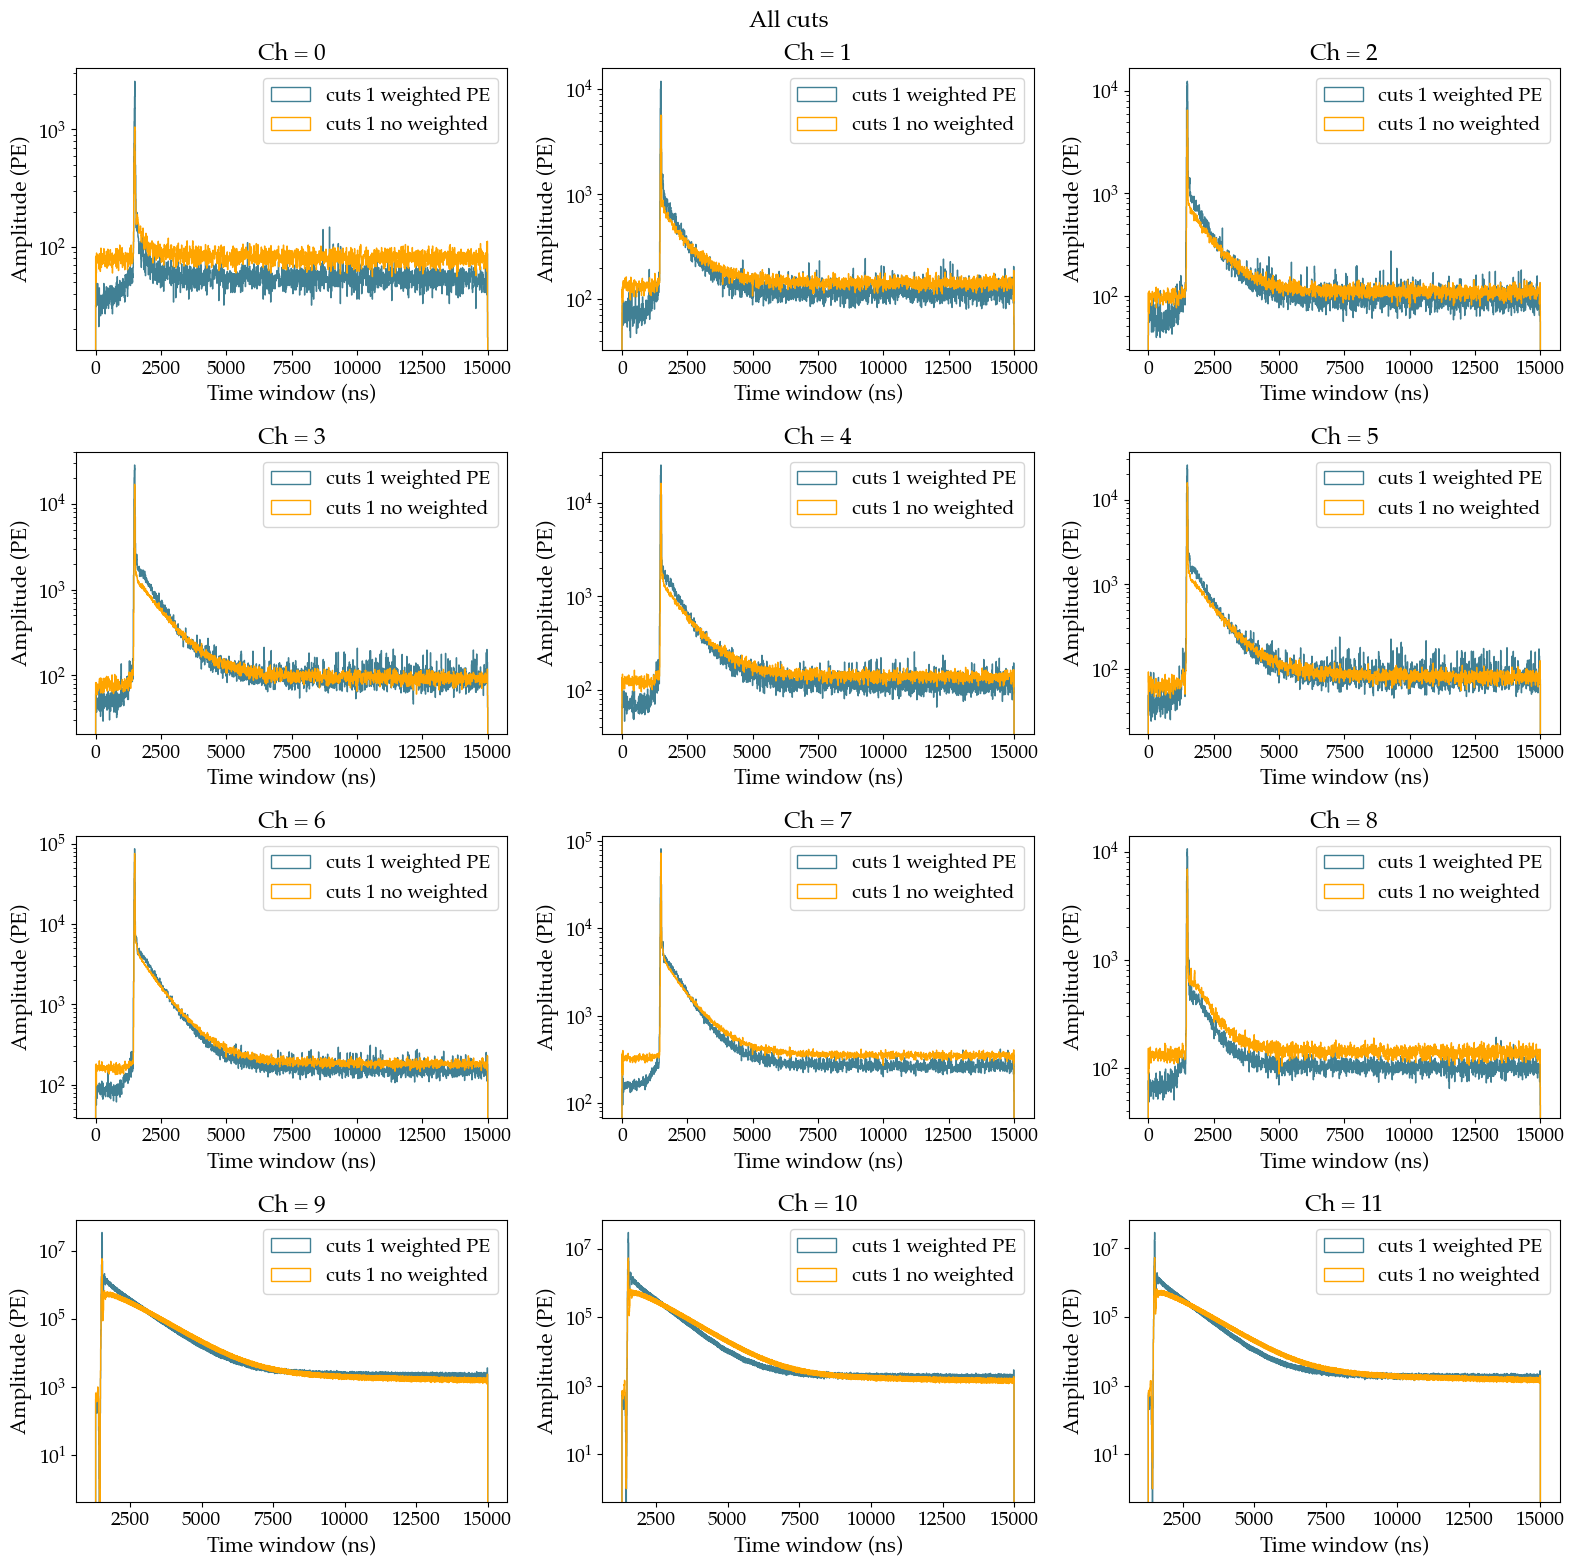

In [162]:
sel_dates = list(idx_max_cuts1.keys())
fig, axs = plt.subplots(4, 3, figsize=(16, 16))
for ch in range(12):
    i = int(ch/3)
    j = ch%3
    print(ch)
    try:
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        vals2 = np.concatenate([2*idx_max_cuts2[date][ch] for date in sel_dates])
        h2    = np.concatenate([height_sg_cuts2[date][ch] for date in sel_dates])
    
        axs[i][j].hist(vals1, weights=h1, bins=1875, histtype='step', label='cuts 1 weighted PE', color=fav_col)
        #axs[i][j].hist(vals2, weights=h2, bins=1875, histtype='step', label='cuts 2 weighted PE', color='orange')
        axs[i][j].hist(vals1,             bins=1875, histtype='step', label='cuts 1 no weighted', color='orange')
        axs[i][j].set_title(f'Ch = {ch}')
        axs[i][j].set_xlabel('Time window (ns)', fontsize=15)
        axs[i][j].set_ylabel('Amplitude (PE)',  fontsize=15)
        axs[i][j].set_yscale('log')
        axs[i][j].legend()
    except (KeyError, ValueError):
        continue
plt.suptitle('All cuts')
plt.tight_layout()
plt.show()

0
1
2
3
4
5
6
7
8
9
10
11


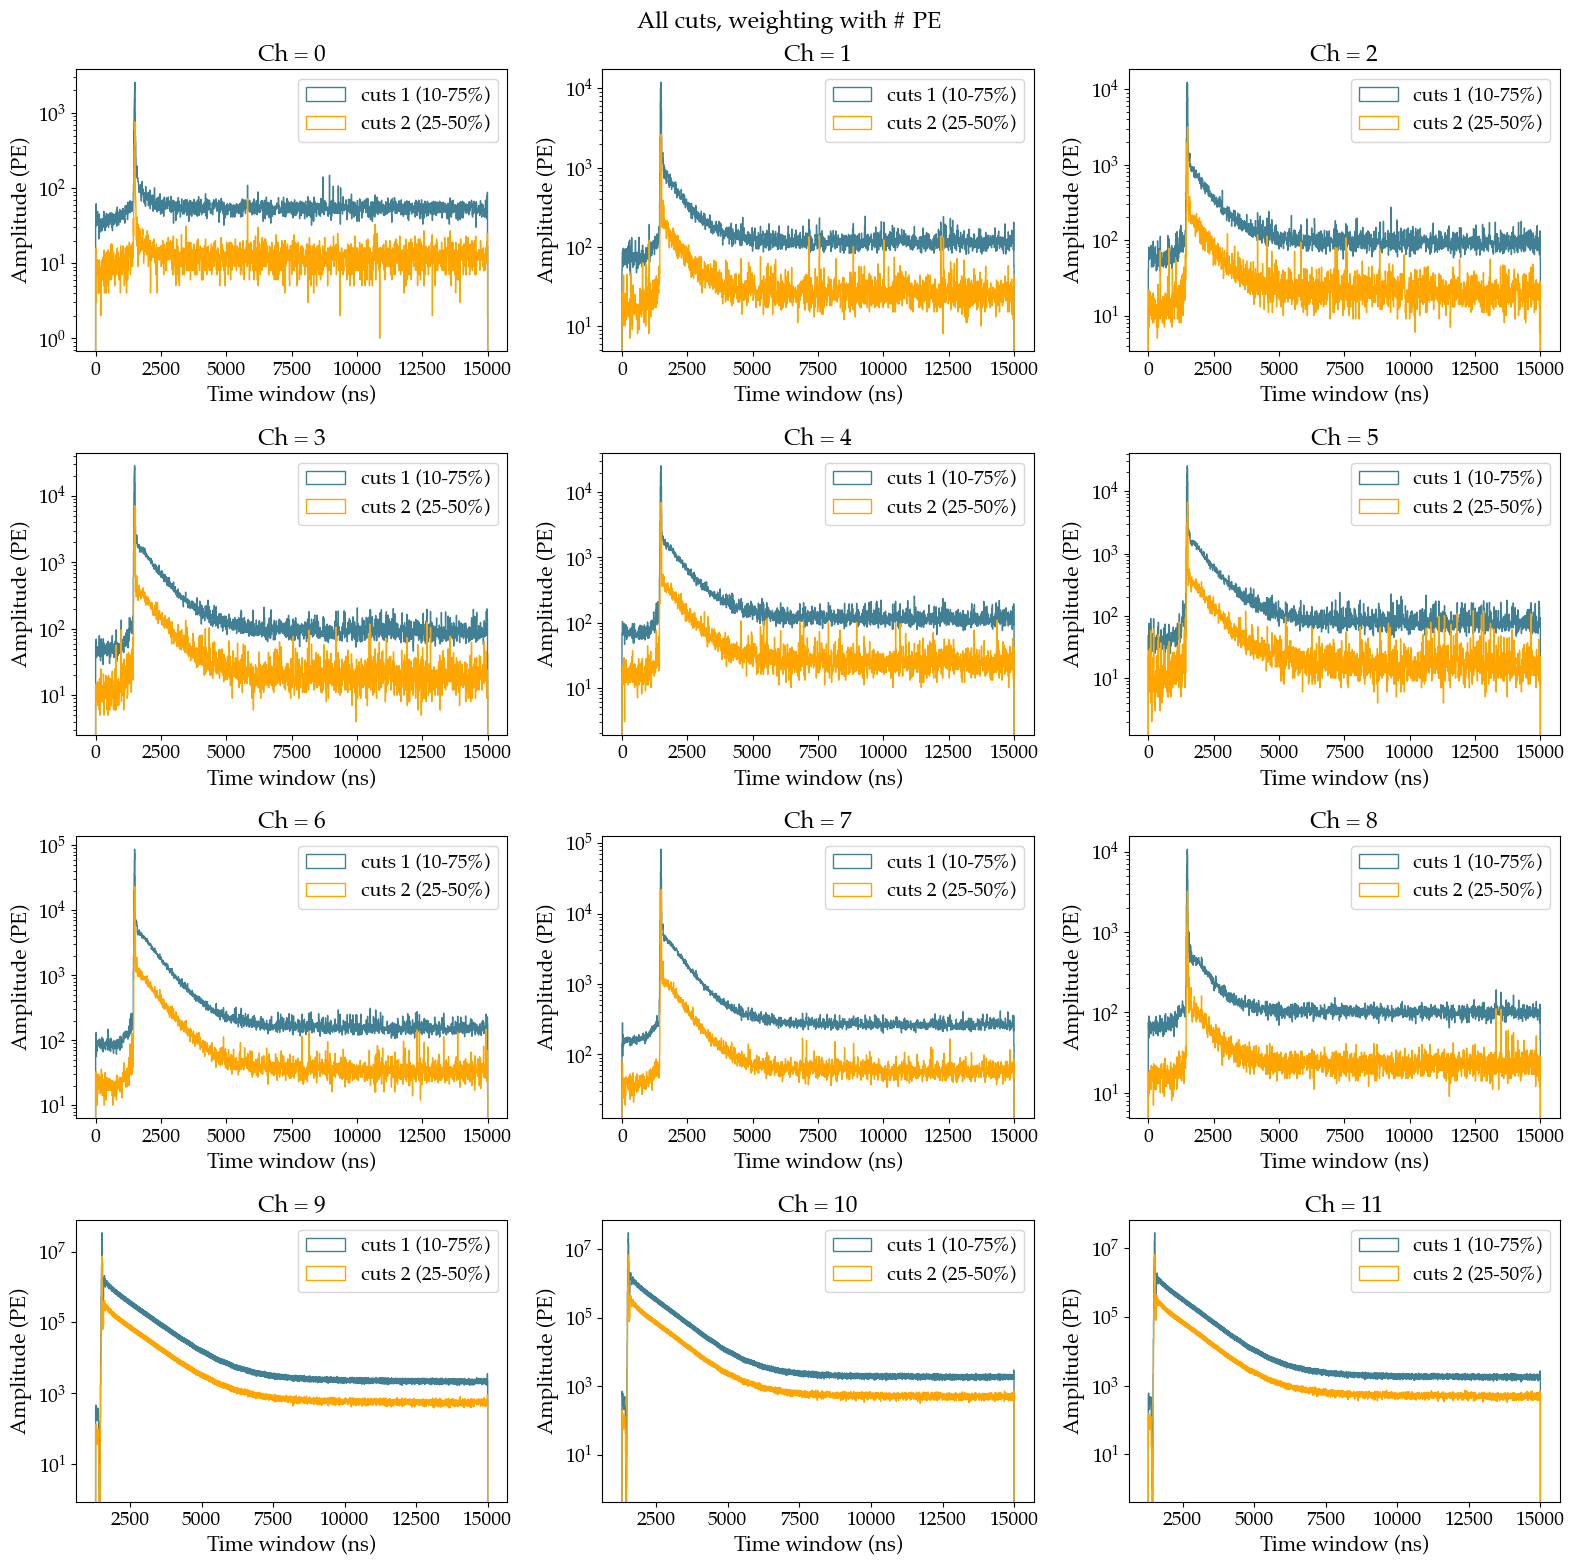

In [163]:
sel_dates = list(idx_max_cuts1.keys())
fig, axs = plt.subplots(4, 3, figsize=(16, 16))
for ch in range(12):
    i = int(ch/3)
    j = ch%3
    print(ch)
    try:
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        vals2 = np.concatenate([2*idx_max_cuts2[date][ch] for date in sel_dates])
        h2    = np.concatenate([height_sg_cuts2[date][ch] for date in sel_dates])
    
        axs[i][j].hist(vals1, weights=h1, bins=1875, histtype='step', label='cuts 1 (10-75%)', color=fav_col)
        axs[i][j].hist(vals2, weights=h2, bins=1875, histtype='step', label='cuts 2 (25-50%)', color='orange')
        axs[i][j].set_title(f'Ch = {ch}')
        axs[i][j].set_xlabel('Time window (ns)', fontsize=15)
        axs[i][j].set_ylabel('Amplitude (PE)',  fontsize=15)
        axs[i][j].set_yscale('log')
        axs[i][j].legend()
    except (KeyError, ValueError):
        continue
plt.suptitle('All cuts, weighting with # PE')
plt.tight_layout()
plt.show()

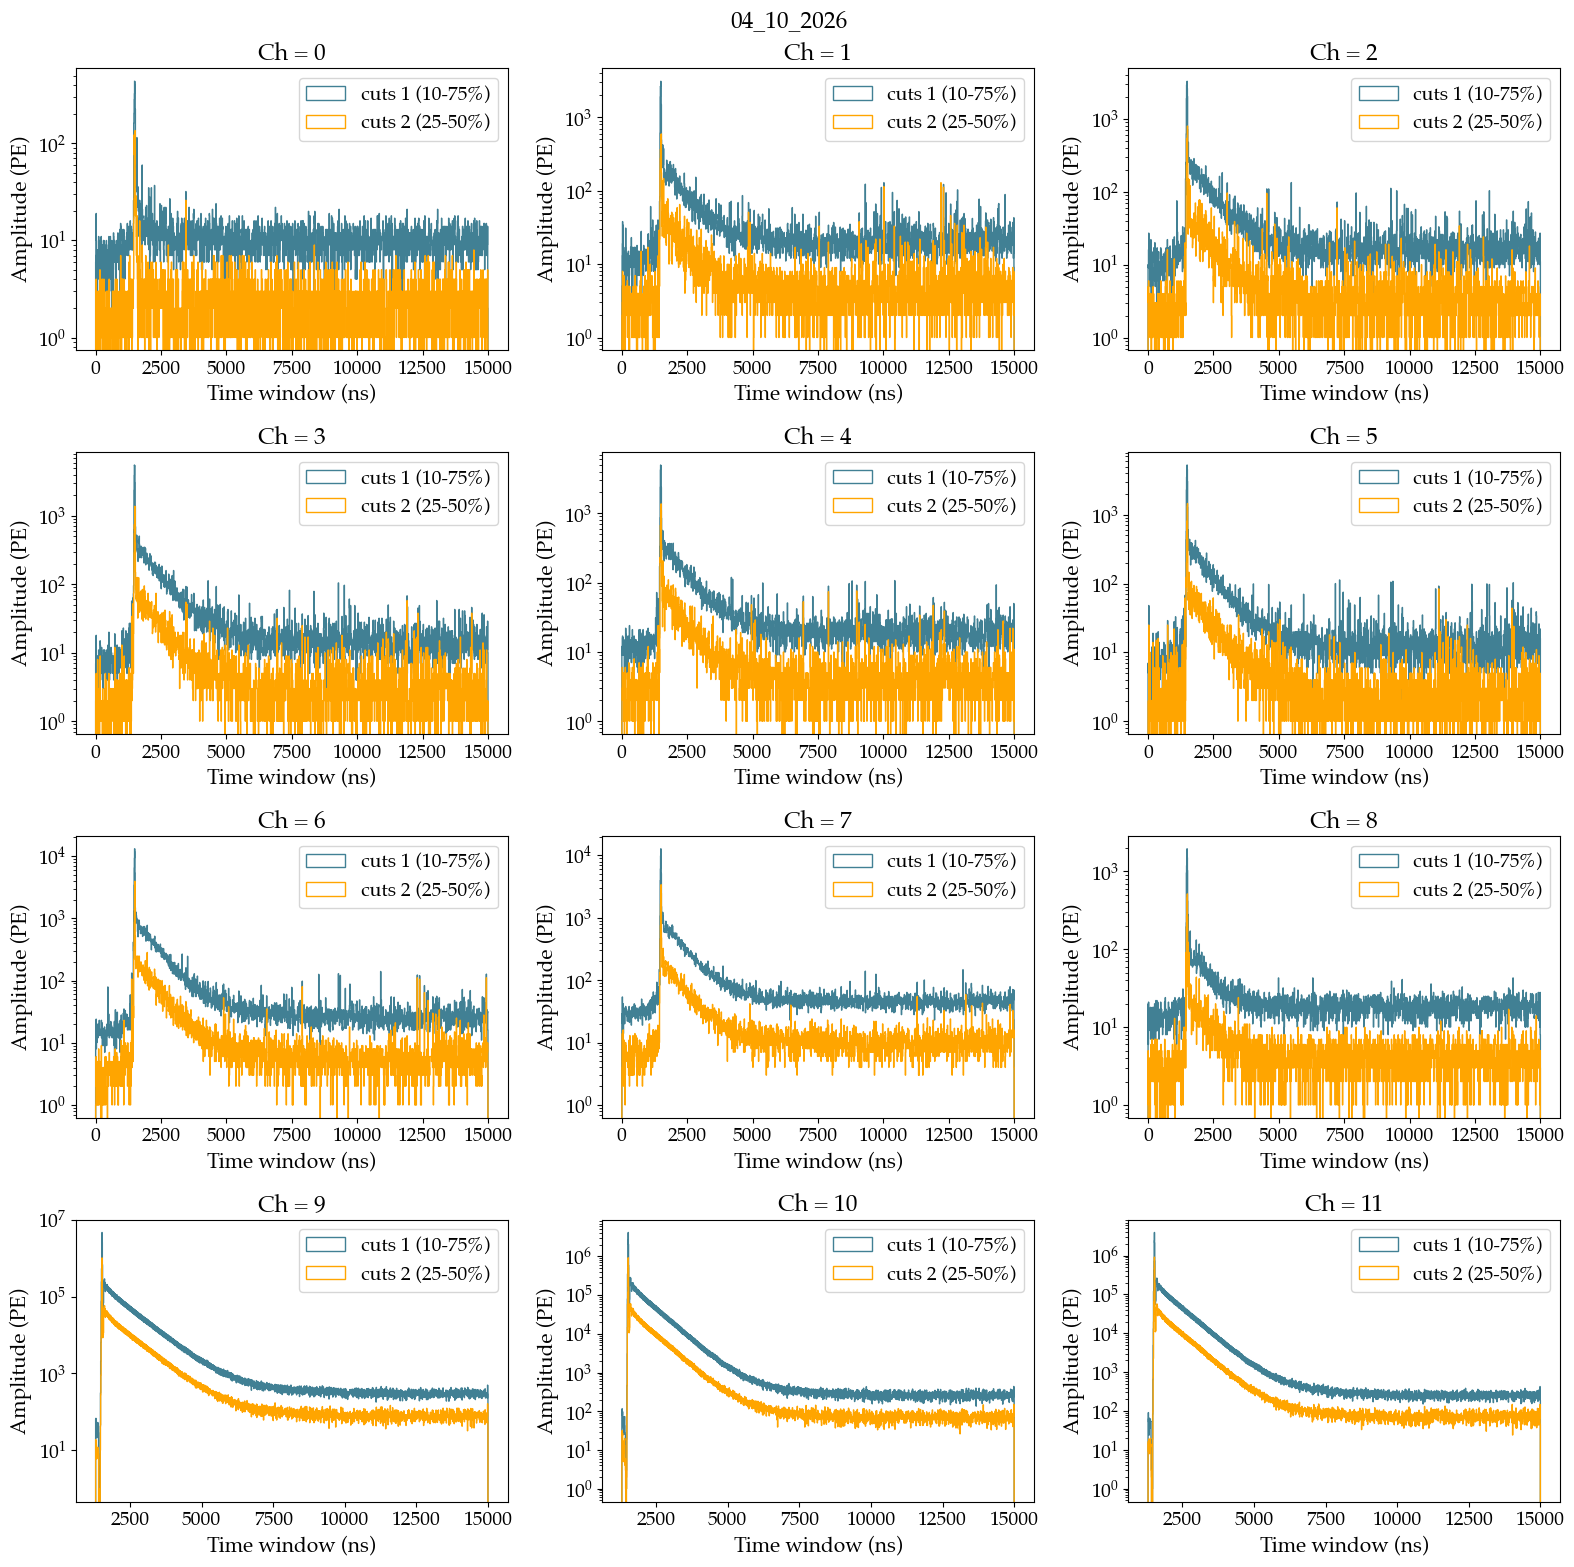

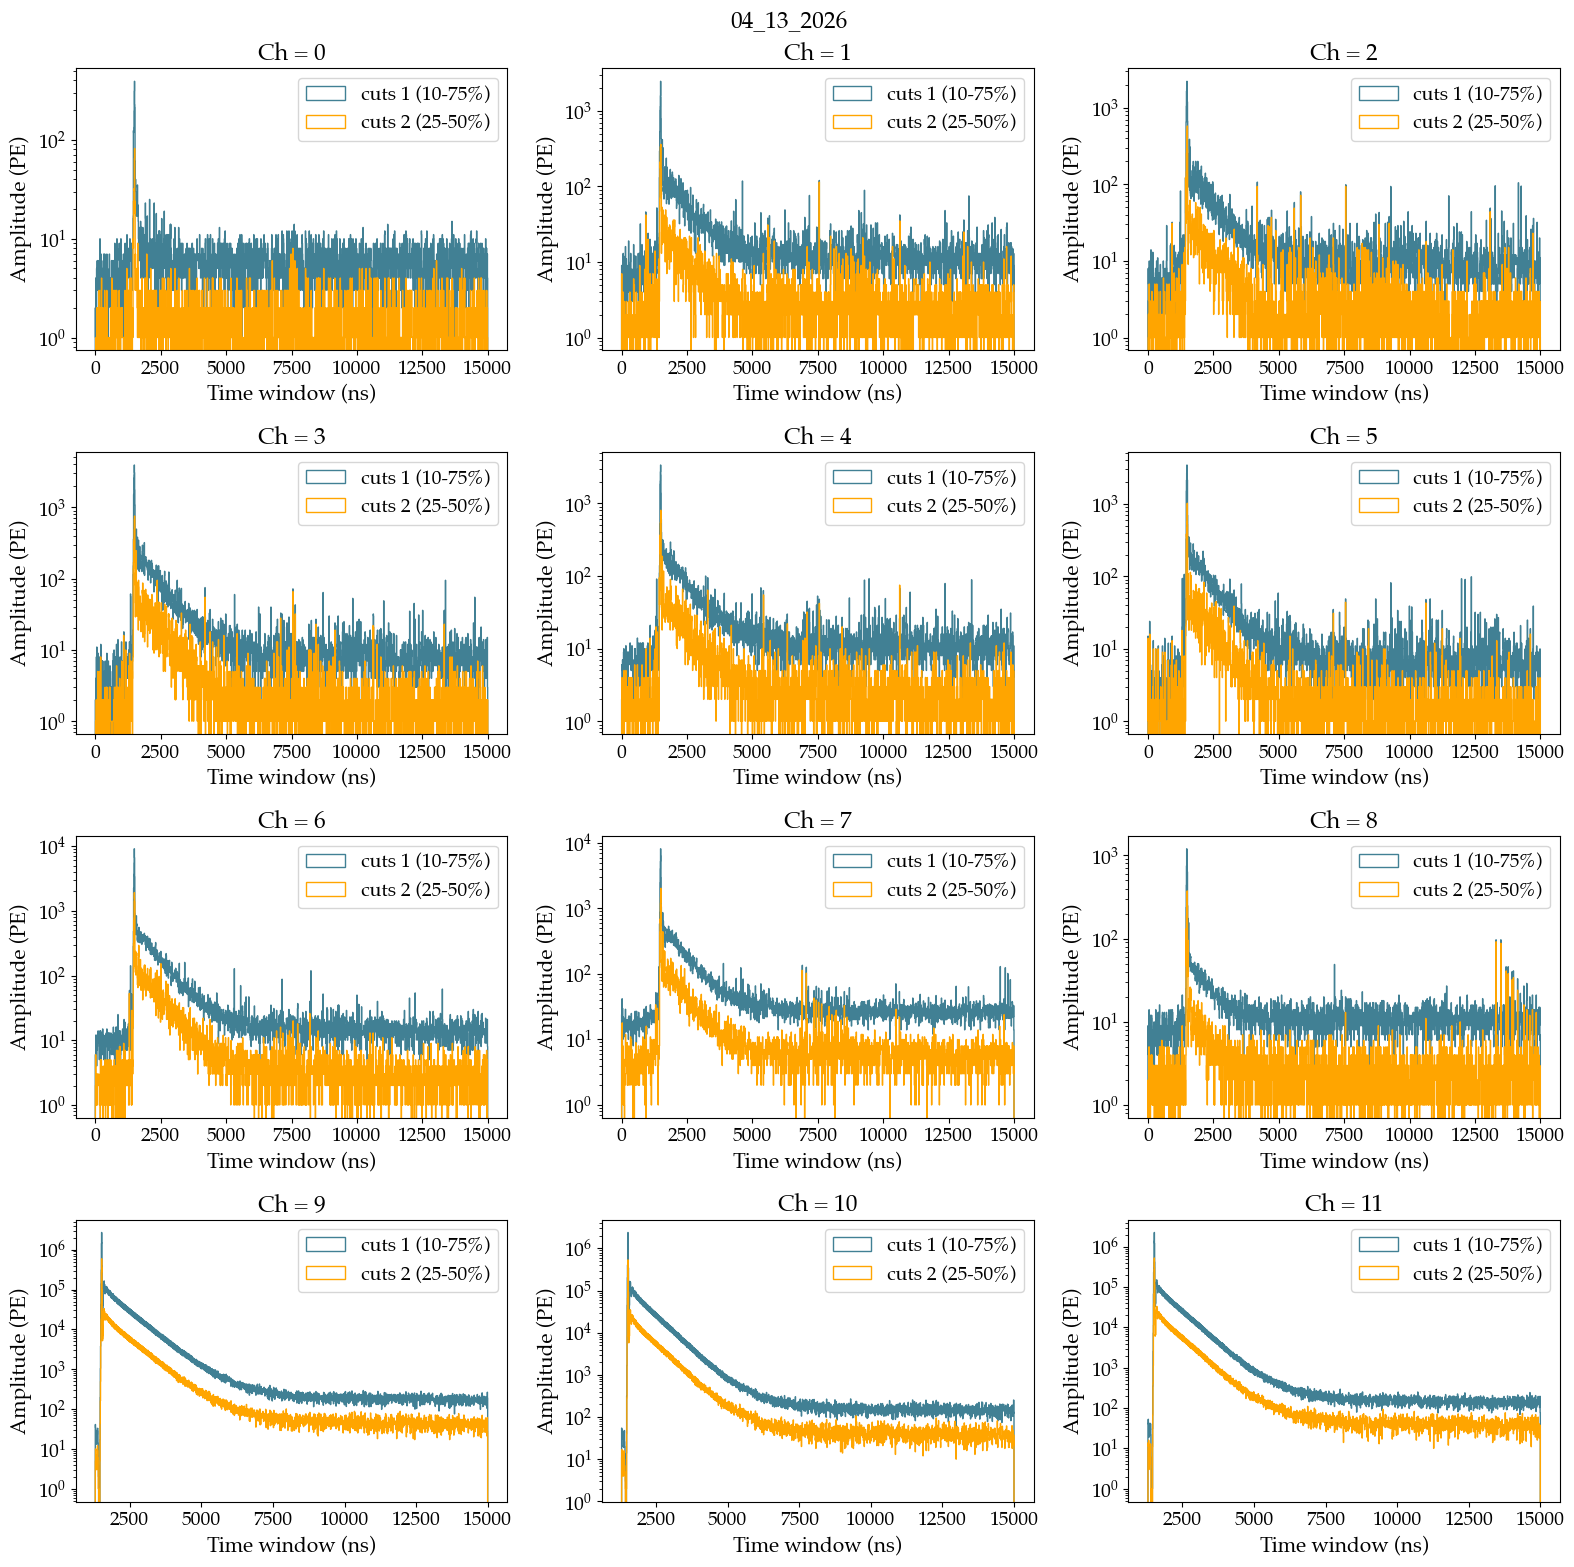

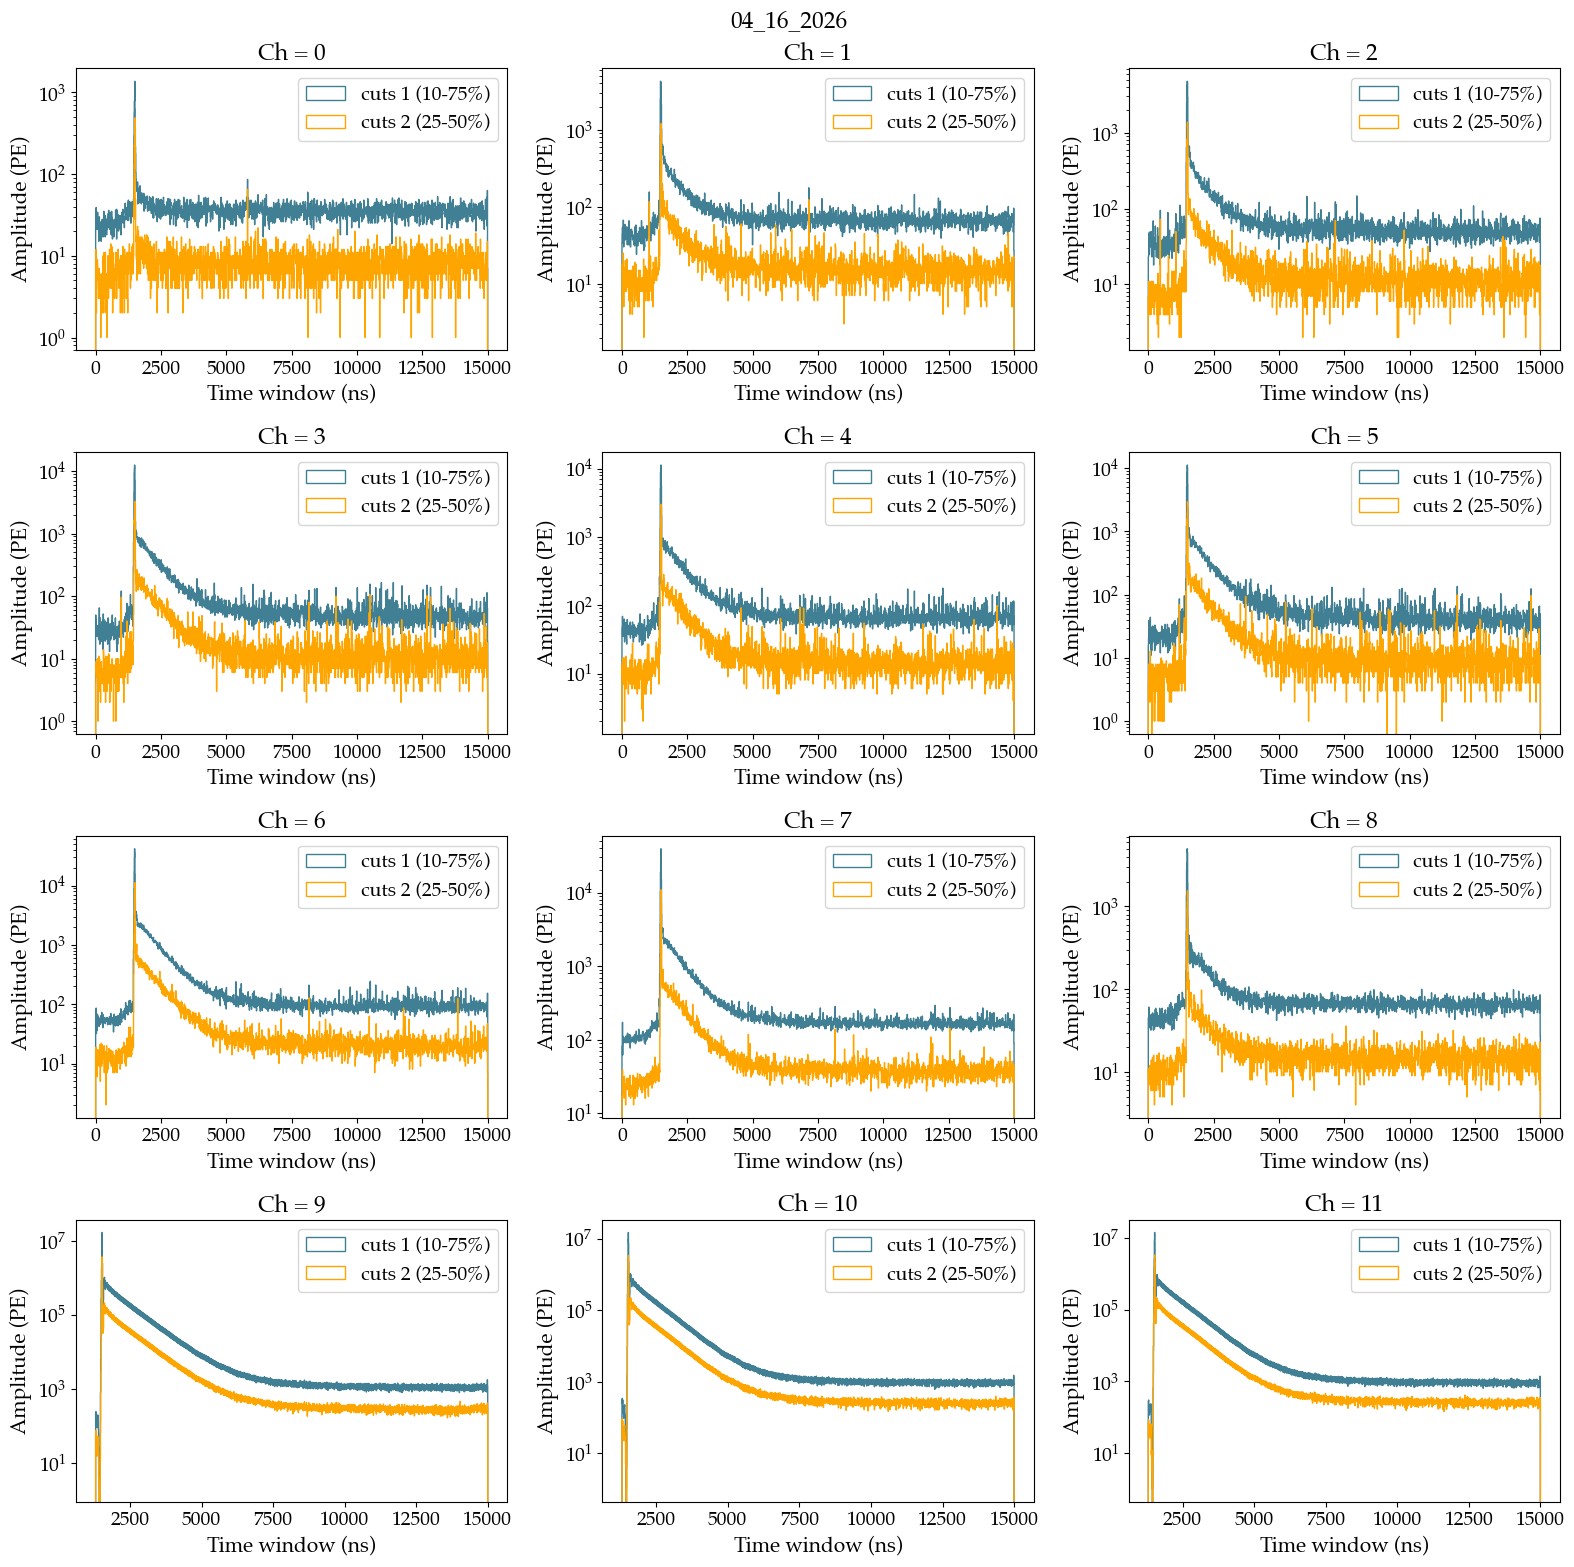

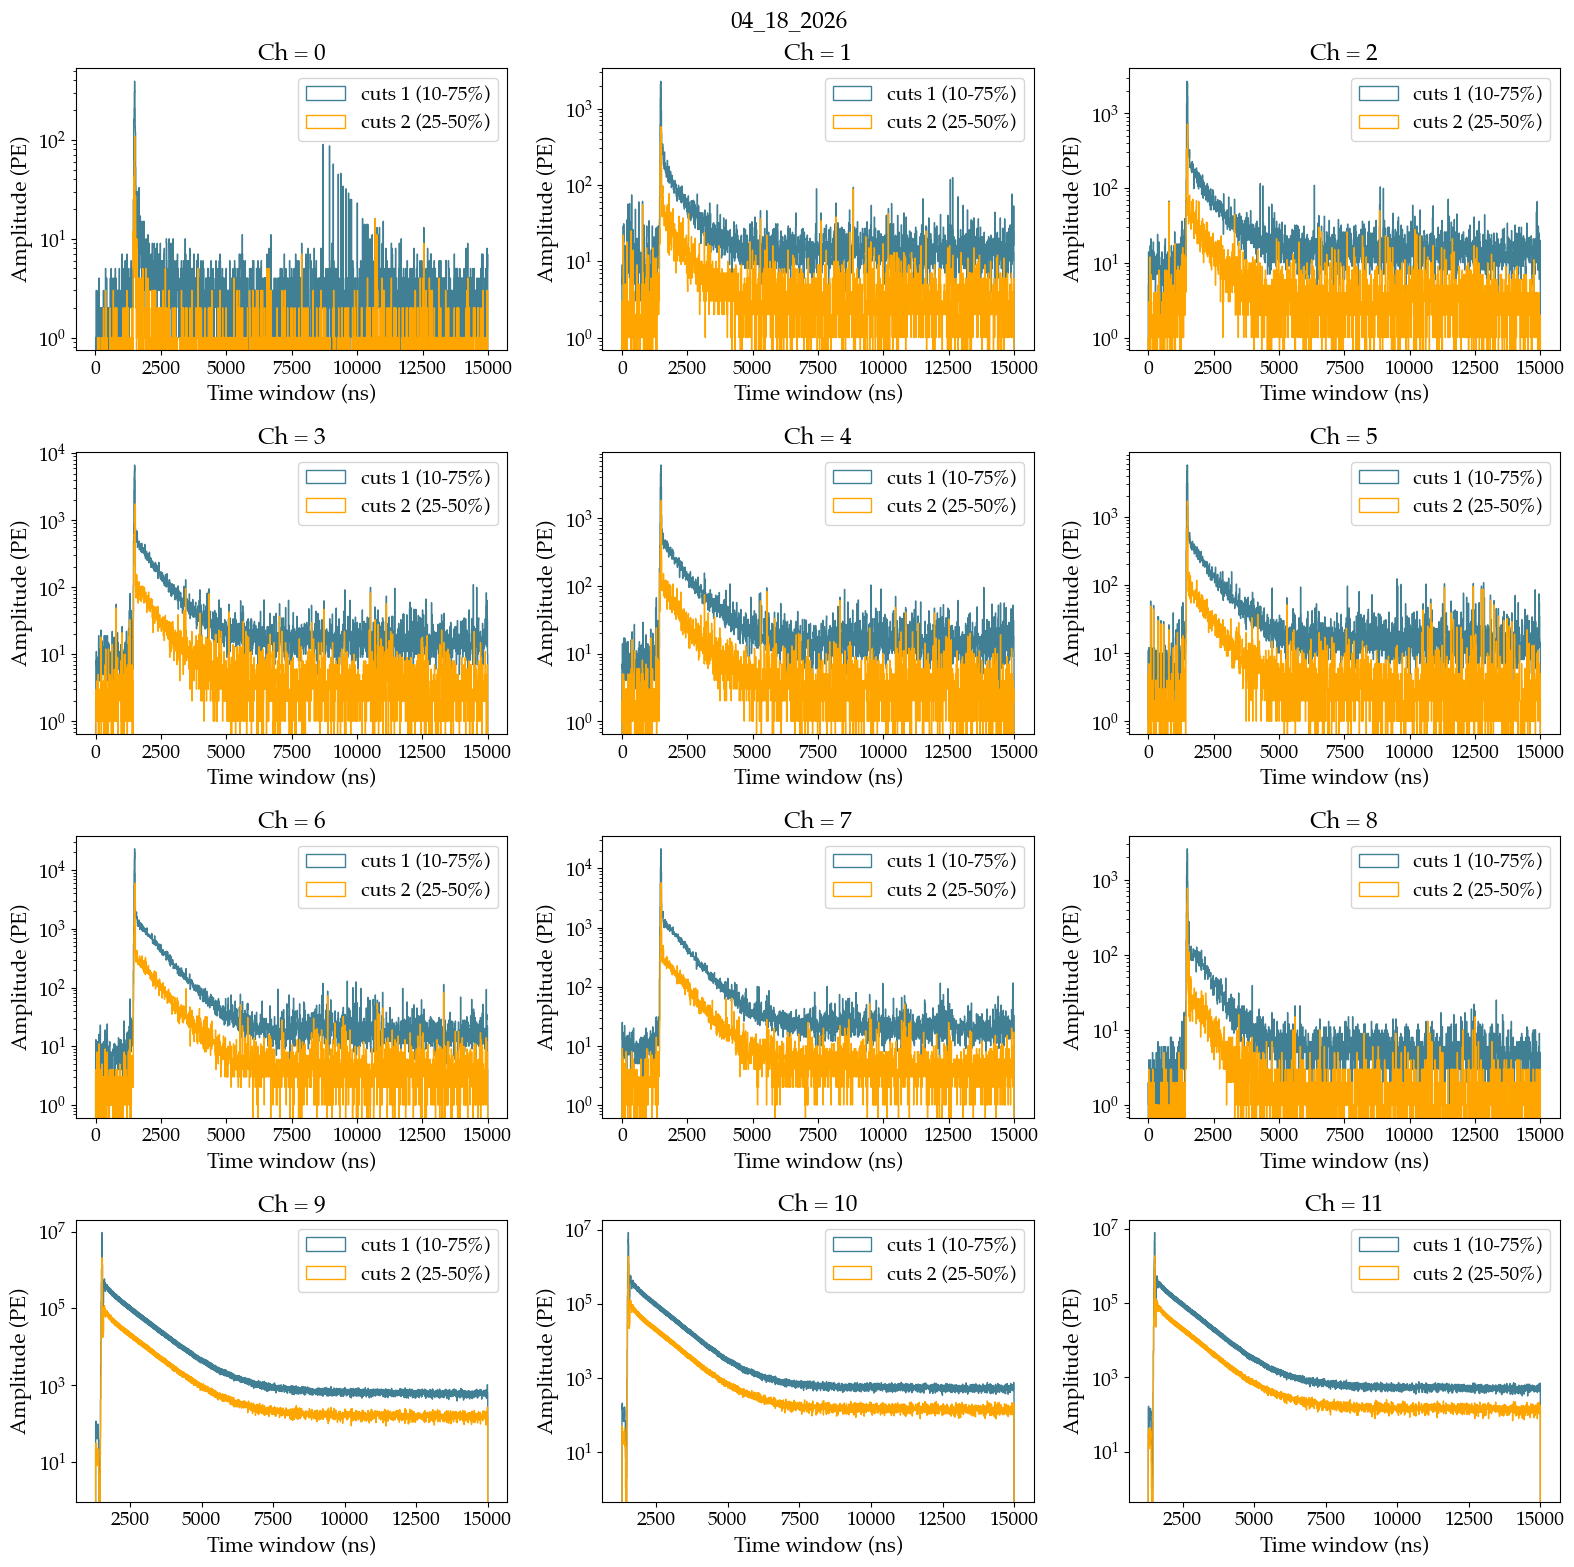

In [164]:
sel_dates = list(idx_max_cuts1.keys())
for date in sel_dates:
    fig, axs = plt.subplots(4, 3, figsize=(16, 16))
    for ch in range(12):
        i = int(ch/3)
        j = ch%3
        try:
            vals1 = 2*idx_max_cuts1[date][ch]
            vals2 = 2*idx_max_cuts2[date][ch]
            h1    = height_sg_cuts1[date][ch]
            h2    = height_sg_cuts2[date][ch]

            axs[i][j].hist(vals1, weights=h1, bins=1875, histtype='step', label='cuts 1 (10-75%)', color=fav_col)
            axs[i][j].hist(vals2, weights=h2, bins=1875, histtype='step', label='cuts 2 (25-50%)', color='orange')
            axs[i][j].set_title(f'Ch = {ch}')
            axs[i][j].set_xlabel('Time window (ns)', fontsize=15)
            axs[i][j].set_ylabel('Amplitude (PE)',  fontsize=15)
            axs[i][j].set_yscale('log')
            axs[i][j].legend()
        except KeyError:
            continue
    plt.suptitle(date)
    plt.tight_layout()
    plt.show()

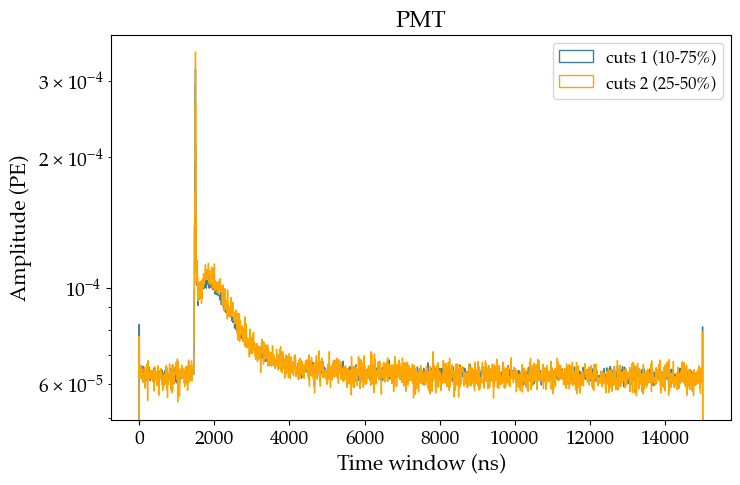

In [166]:
pmt_ch = 12
sel_dates = ['04_16_2026', '04_18_2026']
plt.hist(np.concatenate([2*idx_max_cuts1[date][pmt_ch] for date in sel_dates]), bins=1874, histtype='step', label='cuts 1 (10-75%)', density=True, color=fav_col)
plt.hist(np.concatenate([2*idx_max_cuts2[date][pmt_ch] for date in sel_dates]), bins=1874, histtype='step', label='cuts 2 (25-50%)', density=True, color='orange')
plt.title('PMT')
plt.xlabel('Time window (ns)', fontsize=15)
plt.ylabel('Amplitude (PE)',  fontsize=15)
plt.yscale('log')
plt.legend(fontsize=12)
plt.show()

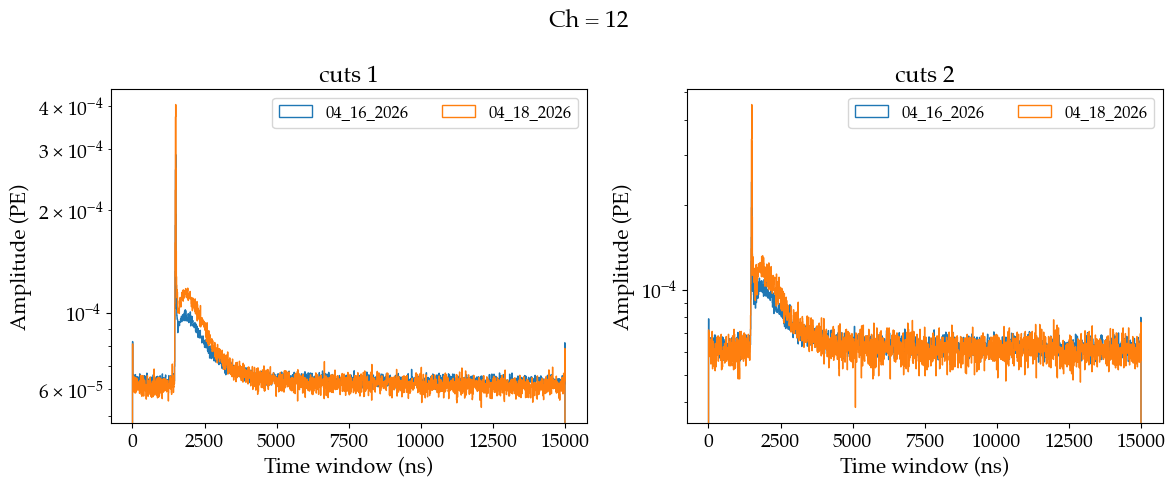

In [167]:
pmt_ch = 12
sel_dates = ['04_16_2026', '04_18_2026']
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for date in sel_dates:
    axs[0].hist(2*idx_max_cuts1[date][pmt_ch], bins=1874, histtype='step', label=date, density=True)
    axs[1].hist(2*idx_max_cuts2[date][pmt_ch], bins=1874, histtype='step', label=date, density=True)
for ax, title in zip(axs, ['cuts 1', 'cuts 2']):
    ax.set_title(title)
    ax.set_xlabel('Time window (ns)', fontsize=15)
    ax.set_ylabel('Amplitude (PE)',  fontsize=15)
    ax.set_yscale('log')
    ax.legend(fontsize=12, ncol=2)
plt.suptitle(f'Ch = {pmt_ch}')
plt.tight_layout()
plt.show()

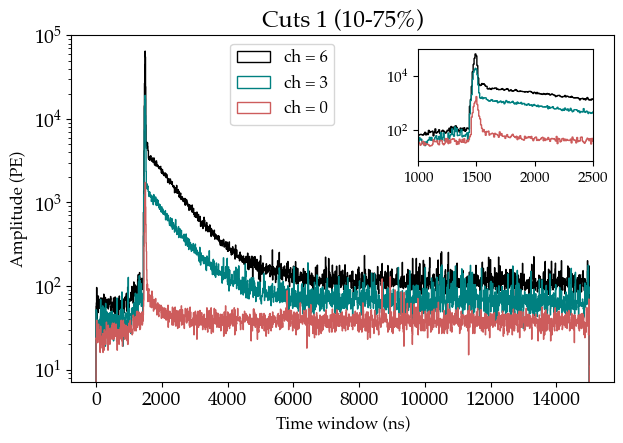

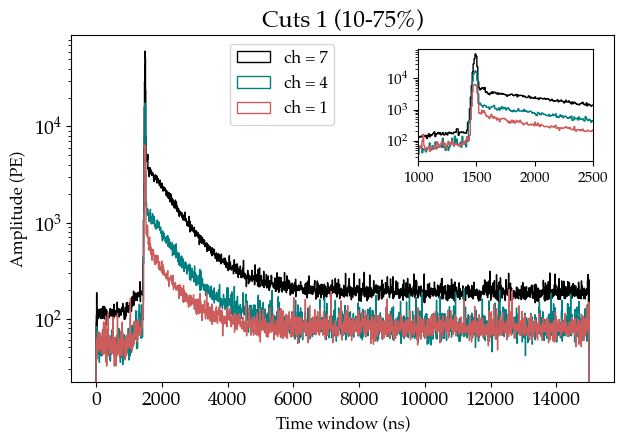

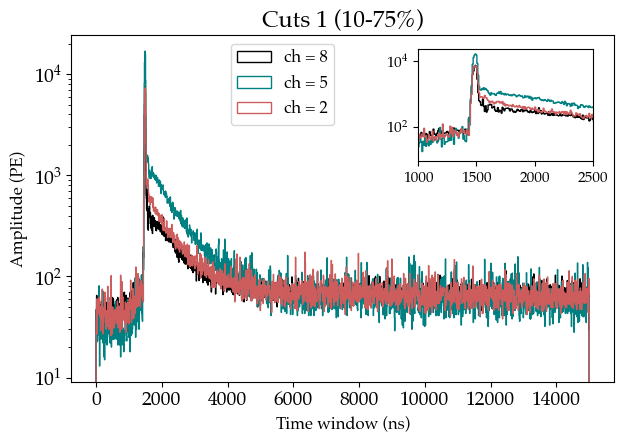

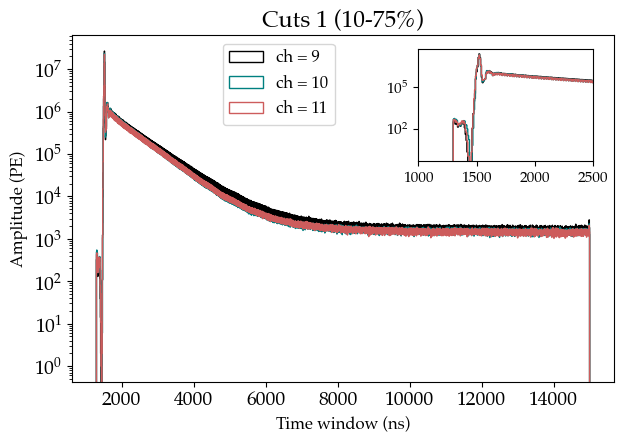

In [199]:
for sel_chs in [[6, 3, 0], [7, 4, 1], [8, 5, 2], [9, 10, 11]]:
    fig = plt.figure(figsize=(7, 4.5))
    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        plt.hist(vals1, weights=h1, bins=1875, histtype='step', label=f'ch = {ch}', color=col)
    
    plt.xlabel('Time window (ns)', fontsize=12)
    plt.ylabel('Amplitude (PE)',   fontsize=12)
    plt.legend(bbox_to_anchor=(0.5, 1), fontsize=12)
    plt.title('Cuts 1 (10-75%)')
    plt.yscale('log')

    ax_inset = fig.add_axes([0.62, 0.60, 0.25, 0.25])
    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        ax_inset.hist(vals1, weights=h1, bins=1875, histtype='step', color=col)

    ax_inset.set_xlim(1000, 2500)
    ax_inset.tick_params(axis='x', labelsize=11)
    ax_inset.tick_params(axis='y', labelsize=11)
    ax_inset.set_yscale('log')
    plt.show()

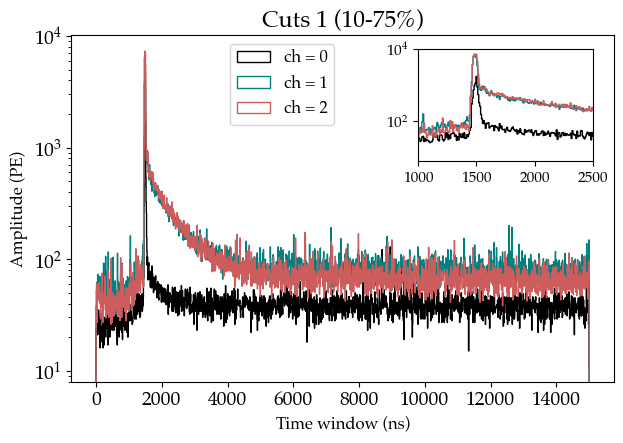

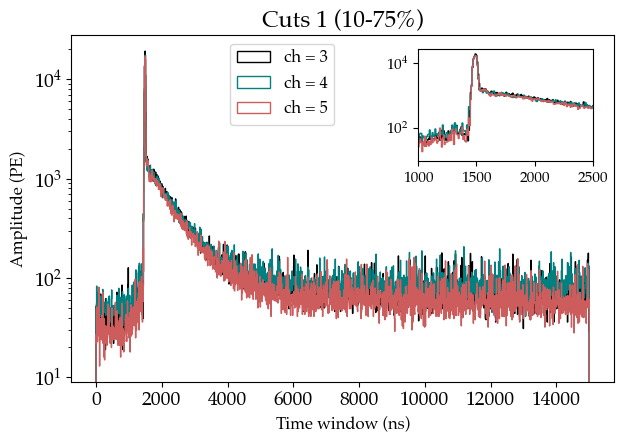

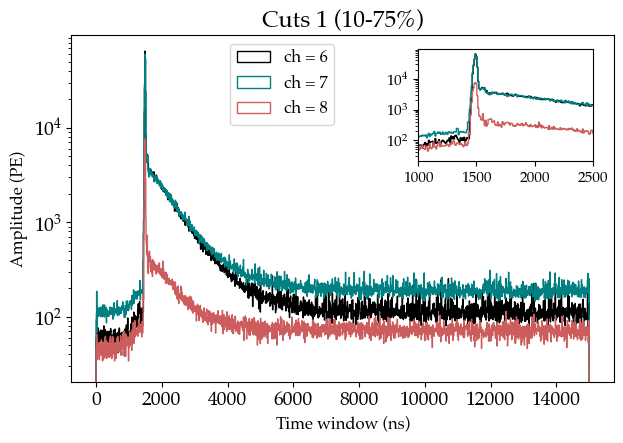

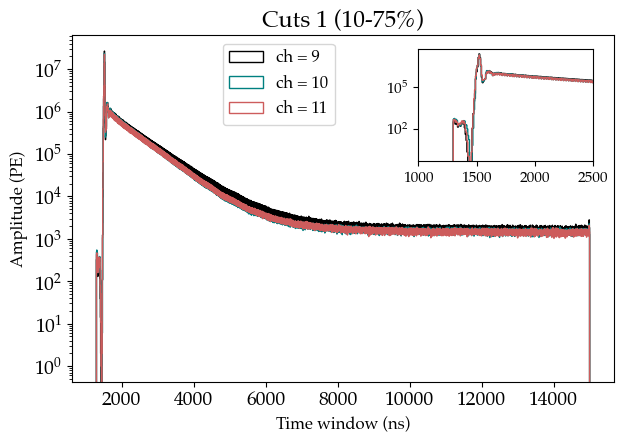

In [211]:
for sel_chs in [[0, 1, 2], [3, 4, 5], [6, 7, 8], [9, 10, 11]]:
    fig = plt.figure(figsize=(7, 4.5))
    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        plt.hist(vals1, weights=h1, bins=1875, histtype='step', label=f'ch = {ch}', color=col)
    
    plt.xlabel('Time window (ns)', fontsize=12)
    plt.ylabel('Amplitude (PE)',   fontsize=12)
    plt.legend(bbox_to_anchor=(0.5, 1), fontsize=12)
    plt.title('Cuts 1 (10-75%)')
    plt.yscale('log')

    ax_inset = fig.add_axes([0.62, 0.60, 0.25, 0.25])
    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        ax_inset.hist(vals1, weights=h1, bins=1875, histtype='step', color=col)

    ax_inset.set_xlim(1000, 2500)
    ax_inset.tick_params(axis='x', labelsize=11)
    ax_inset.tick_params(axis='y', labelsize=11)
    ax_inset.set_yscale('log')
    plt.show()

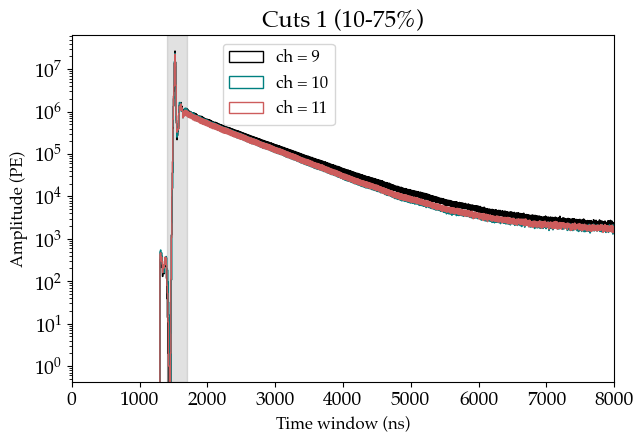

In [216]:
for sel_chs in [[9, 10, 11]]:
    fig = plt.figure(figsize=(7, 4.5))
    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        plt.hist(vals1, weights=h1, bins=1875, histtype='step', label=f'ch = {ch}', color=col)
    
    plt.axvspan(1400, 1700, alpha=0.2, color='dimgrey')
    plt.xlabel('Time window (ns)', fontsize=12)
    plt.ylabel('Amplitude (PE)',   fontsize=12)
    plt.legend(bbox_to_anchor=(0.5, 1), fontsize=12)
    plt.title('Cuts 1 (10-75%)')
    plt.yscale('log')
    plt.xlim(0, 8000)
    plt.show()

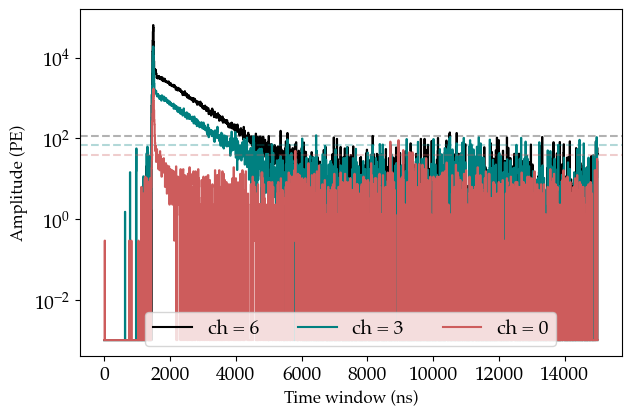

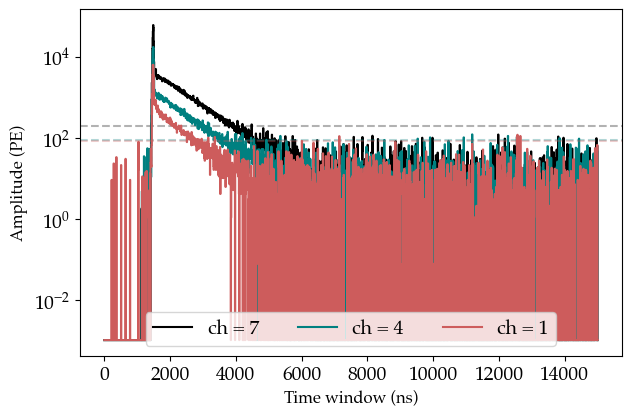

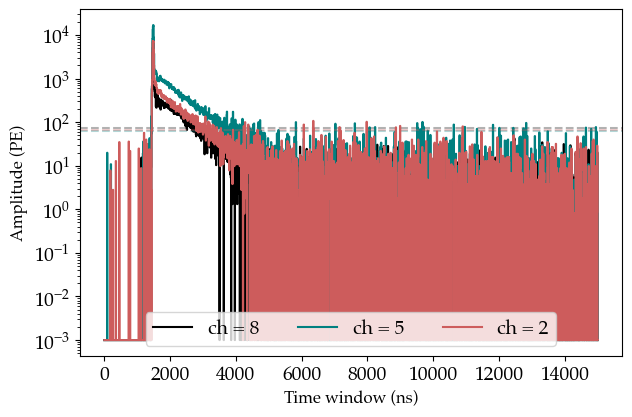

In [191]:
baseline_window = (8000, 15000)

for sel_chs in [[6, 3, 0], [7, 4, 1], [8, 5, 2]]:
    fig = plt.figure(figsize=(7, 4.5))

    for ch, col in zip(sel_chs, ['k', 'teal', 'indianred']):

        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        
        # histogram
        y, x = np.histogram(vals1, bins=1875, weights=h1)
        xc = 0.5 * (x[:-1] + x[1:])

        # baseline from histogram
        mask_baseline = (xc > baseline_window[0]) & (xc < baseline_window[1])
        baseline = np.mean(y[mask_baseline])

        # subtract baseline (correct place!)
        y_corr = y - baseline
        y_corr[y_corr <= 0] = 1e-3  # for log scale

        plt.step(xc, y_corr, where='mid', label=f'ch = {ch}', color=col)
        plt.axhline(baseline, color=col, linestyle='--', alpha=0.3)

    plt.xlabel('Time window (ns)', fontsize=12)
    plt.ylabel('Amplitude (PE)', fontsize=12)
    plt.yscale('log')
    plt.legend(loc='lower center', ncol=3)

    plt.show()

## Compute gamma peak after cuts:

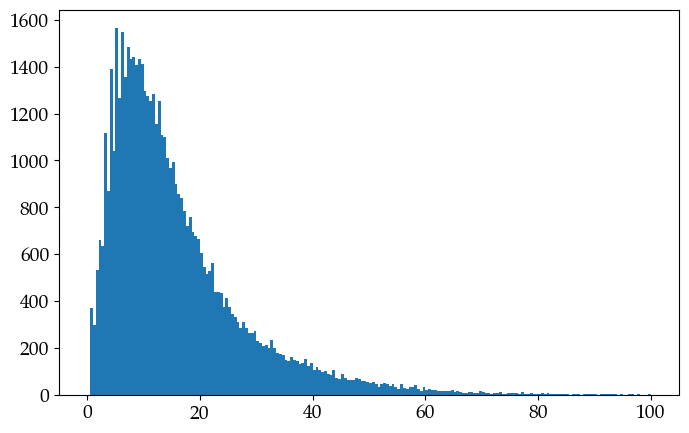

In [131]:
test9  = [np.sum(val) for val in result[2][9]]
test10 = [np.sum(val) for val in result[2][10]]
test11 = [np.sum(val) for val in result[2][11]]

len(test9), len(test10), len(test11)

plt.hist(test9+test10+test11, bins=200, range=(0, 100));

In [149]:
all_params = ['sum_trigg_chs1',
              'sum_trigg_chs2']

data_lists = {param: {} for param in all_params}
start_time = time.time()

for ifile, sipm_file in enumerate(sorted_files):
    
    if ifile % 20 == 0:
        print(f"Processing file {ifile}/{len(sorted_files)}, {time.time() - start_time}")

    result = process_file(sipm_file)
    if result is None:
        continue

    date, _ = extract_date_and_number(sipm_file)

    if date not in data_lists['sum_trigg_chs1']:
        for param in all_params:
            data_lists[param][date] = {ch: [] for ch in trigger_chs}

    d1 = data_lists['sum_trigg_chs1'][date]
    d2 = data_lists['sum_trigg_chs2'][date]

    for ch in trigger_chs:
        if is_non_empty(result[2][ch]):
            vals1 = np.fromiter((np.sum(v) for v in result[2][ch]), dtype=float)
            if vals1.size > 0:
                d1[ch].append(vals1)

        if is_non_empty(result[3][ch]):
            vals2 = np.fromiter((np.sum(v) for v in result[3][ch]), dtype=float)
            if vals2.size > 0:
                d2[ch].append(vals2)
                
final_results = {param: {} for param in all_params}

for param in all_params:
    for date, ch_dict in data_lists[param].items():
        final_results[param][date] = {}

        for ch, array_list in ch_dict.items():
            if not array_list:
                continue  # skip empty

            final_results[param][date][ch] = np.concatenate(array_list)
            
sum_trigg_chs1 = final_results['sum_trigg_chs1']
sum_trigg_chs2 = final_results['sum_trigg_chs2']

end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} s, {elapsed_time/60} min")

Processing file 0/941, 0.0003101825714111328
Processing file 20/941, 7.685861110687256
Processing file 40/941, 15.354387283325195
Processing file 60/941, 22.630059003829956
Processing file 80/941, 29.93956232070923
Processing file 100/941, 37.22557210922241
Processing file 120/941, 44.61549210548401
Processing file 140/941, 52.08086013793945
Processing file 160/941, 59.64691710472107
Processing file 180/941, 67.09003210067749
Processing file 200/941, 74.7125391960144
Processing file 220/941, 82.49604296684265
Processing file 240/941, 90.43774819374084
Processing file 260/941, 98.34459328651428
Processing file 280/941, 106.18936920166016
Processing file 300/941, 113.94739627838135
Processing file 320/941, 121.74077320098877
Processing file 340/941, 129.44065833091736
Processing file 360/941, 137.12129831314087
Processing file 380/941, 144.82833814620972
Processing file 400/941, 152.44374442100525
Processing file 420/941, 159.9724612236023
Processing file 440/941, 167.50117230415344
Proc

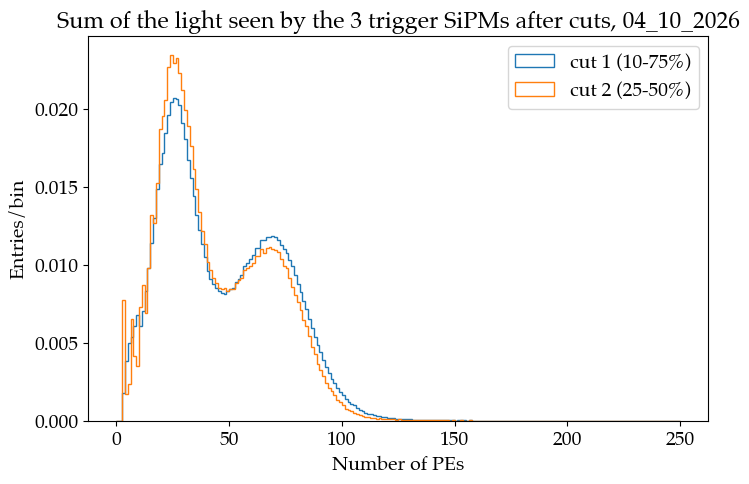

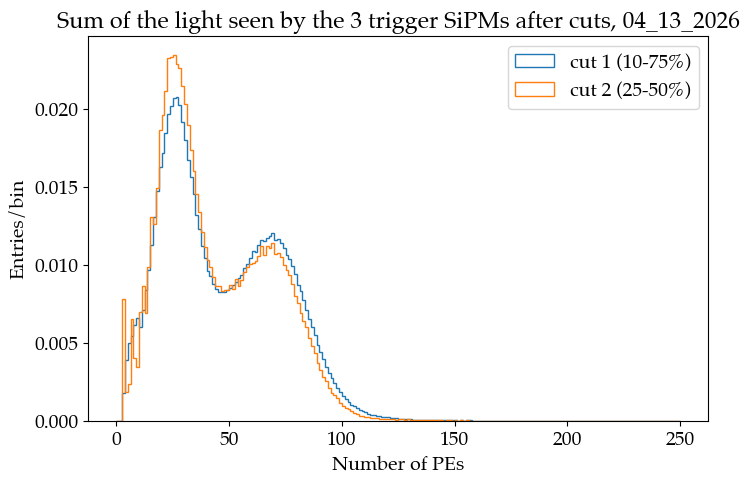

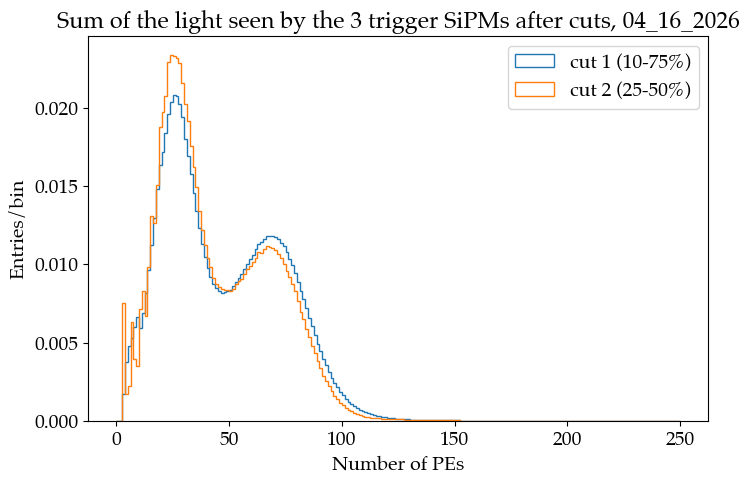

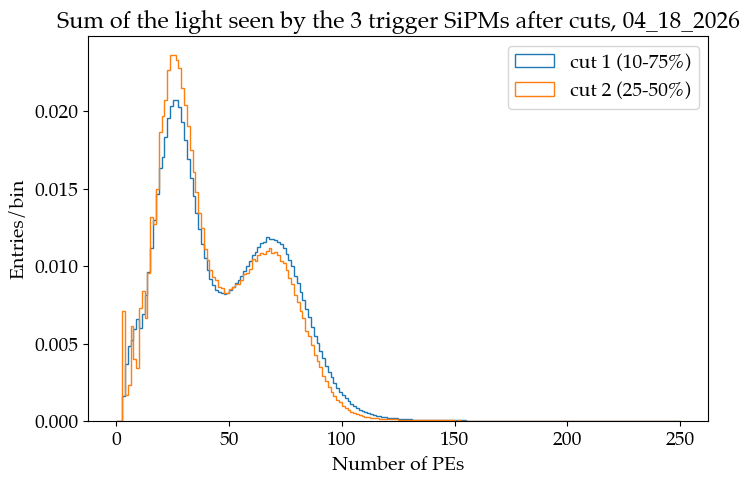

In [174]:
for date in sum_trigg_chs1.keys():
    sum_vals1 = sum_trigg_chs1[date][9] + sum_trigg_chs1[date][10] + sum_trigg_chs1[date][11]
    sum_vals2 = sum_trigg_chs2[date][9] + sum_trigg_chs2[date][10] + sum_trigg_chs2[date][11]
    plt.hist(sum_vals1, bins=200, range=(0, 250), histtype='step', density=True, label='cut 1 (10-75%)')
    plt.hist(sum_vals2, bins=200, range=(0, 250), histtype='step', density=True, label='cut 2 (25-50%)')
    plt.xlabel('Number of PEs')
    plt.ylabel('Entries/bin')
    plt.title(f'Sum of the light seen by the 3 trigger SiPMs after cuts, {date}')
    plt.legend()
    plt.show()

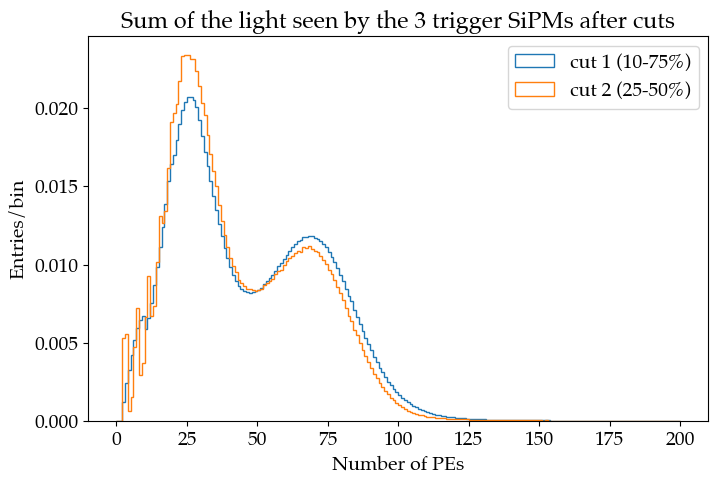

In [173]:
## All dates

all_dates = sum_trigg_chs1.keys()
sum_vals1 = np.concatenate([np.sum([sum_trigg_chs1[date][ch] for ch in [9, 10, 11]], axis=0) for date in all_dates])
sum_vals2 = np.concatenate([np.sum([sum_trigg_chs2[date][ch] for ch in [9, 10, 11]], axis=0) for date in all_dates])
plt.hist(sum_vals1, bins=200, range=(0, 200), histtype='step', density=True, label='cut 1 (10-75%)')
plt.hist(sum_vals2, bins=200, range=(0, 200), histtype='step', density=True, label='cut 2 (25-50%)')
plt.xlabel('Number of PEs')
plt.ylabel('Entries/bin')
plt.title('Sum of the light seen by the 3 trigger SiPMs after cuts')
plt.legend()
plt.show()

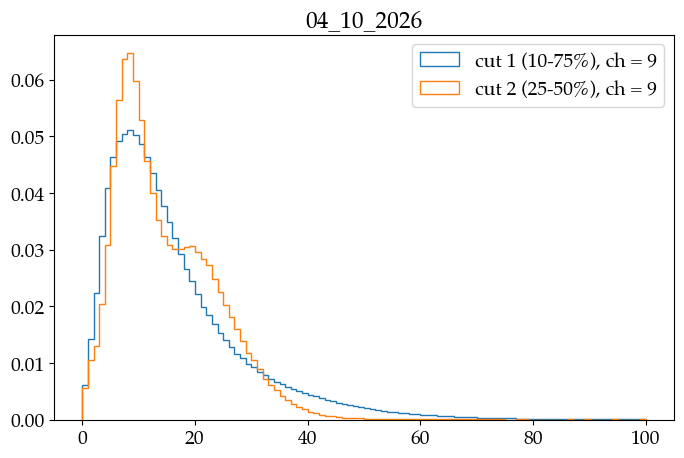

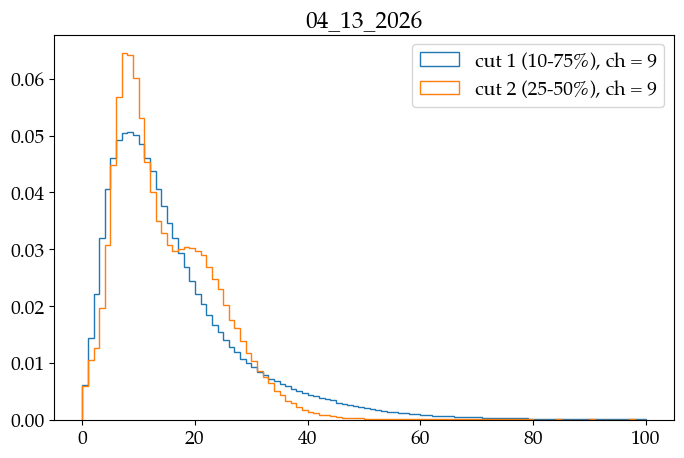

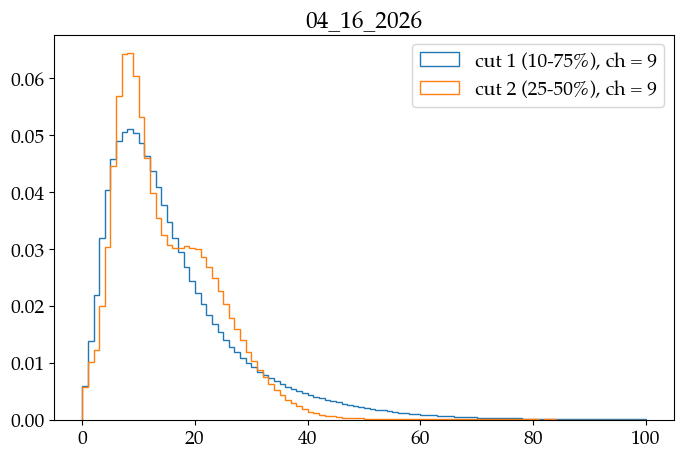

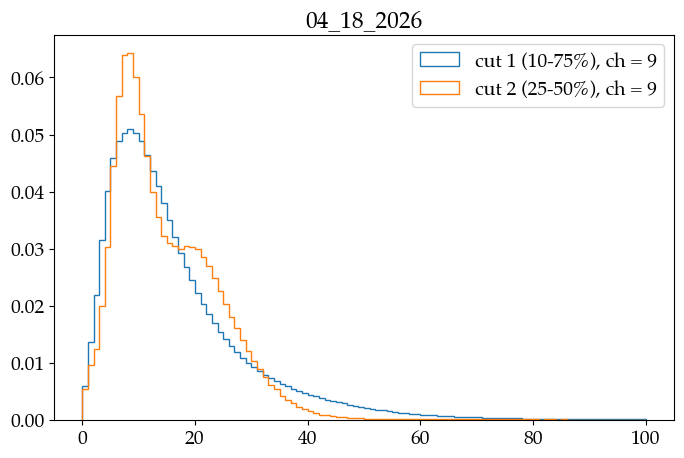

In [161]:
for date in sum_trigg_chs1.keys():
    for ch in trigger_chs[:1]:
        plt.hist(sum_trigg_chs1[date][ch], bins=100, range=(0, 100), histtype='step', density=True, label=f'cut 1 (10-75%), ch = {ch}')
        plt.hist(sum_trigg_chs2[date][ch], bins=100, range=(0, 100), histtype='step', density=True, label=f'cut 2 (25-50%), ch = {ch}')
    plt.legend()
    plt.title(date)
    plt.show()

### Get number of PE detected for each channel

In [230]:
num_PEs_chs = {param: {ch: []
                      for ch in range(12)}
              for param in ['num_PEs_0', 'num_PEs_1', 'num_PEs_2', 'num_PEs_3']}
start_time = time.time()

for ifile, sipm_file in enumerate(sorted_files):
    
    if ifile % 20 == 0:
        print(f"Processing file {ifile}/{len(sorted_files)}, {time.time() - start_time}")

    result = process_file(sipm_file)
    if result is None:
        continue

    date, fnum = extract_date_and_number(sipm_file)
                
    for ch in range(12):
        try:
            if is_non_empty(result[2][ch]):
                num_PEs_chs['num_PEs_0'][ch].append(np.sum(np.round(np.concatenate(result[2][ch])).astype(int)))
                num_PEs_chs['num_PEs_1'][ch].append(np.sum(np.concatenate(result[2][ch])))
            if is_non_empty(result[3][ch]):
                num_PEs_chs['num_PEs_2'][ch].append(np.sum(np.round(np.concatenate(result[3][ch])).astype(int)))
                num_PEs_chs['num_PEs_3'][ch].append(np.sum(np.concatenate(result[3][ch])))
        
        except Exception as e:
            print(f"Error: {date}, {fnum}, {sipm_file}, Ch {ch}: {e}")
            continue
            

end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} s, {elapsed_time/60} min")

Processing file 0/941, 0.0004439353942871094
Processing file 20/941, 6.6488330364227295
Processing file 40/941, 13.242023944854736
Processing file 60/941, 19.434121131896973
Processing file 80/941, 25.56850790977478
Processing file 100/941, 31.738752126693726
Processing file 120/941, 37.893333196640015
Processing file 140/941, 44.0683798789978
Processing file 160/941, 50.22453784942627
Processing file 180/941, 56.55687713623047
Processing file 200/941, 62.712602853775024
Processing file 220/941, 69.16608214378357
Processing file 240/941, 75.92587614059448
Processing file 260/941, 82.28036689758301
Processing file 280/941, 88.77297592163086
Processing file 300/941, 95.02069211006165
Processing file 320/941, 101.31792998313904
Processing file 340/941, 107.57559990882874
Processing file 360/941, 113.80375003814697
Processing file 380/941, 120.08461213111877
Processing file 400/941, 126.32121920585632
Processing file 420/941, 132.54825401306152
Processing file 440/941, 138.8417251110077
Pr

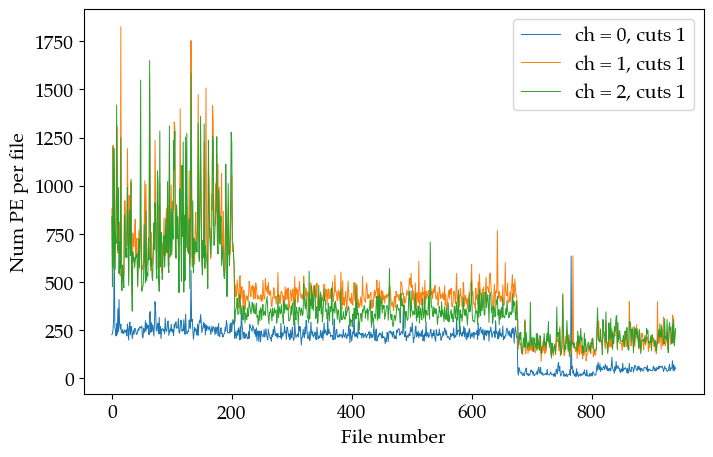

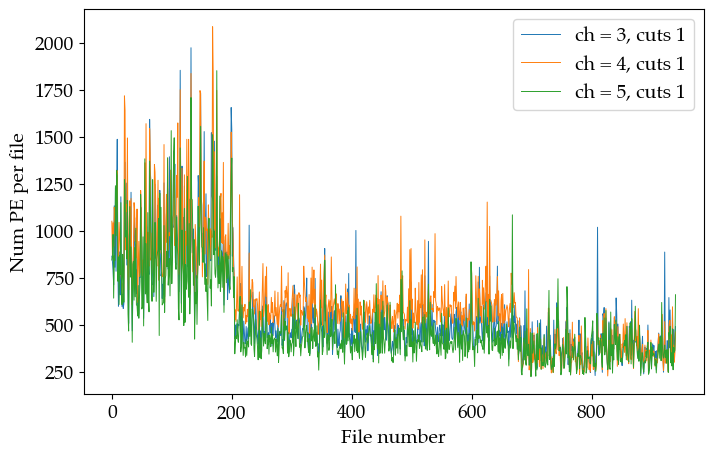

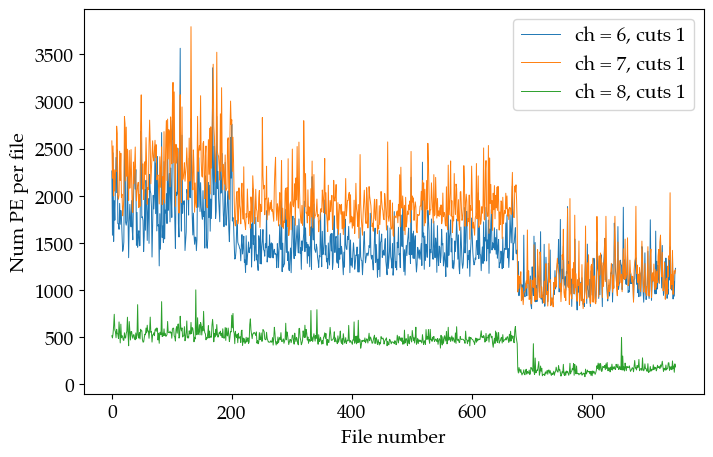

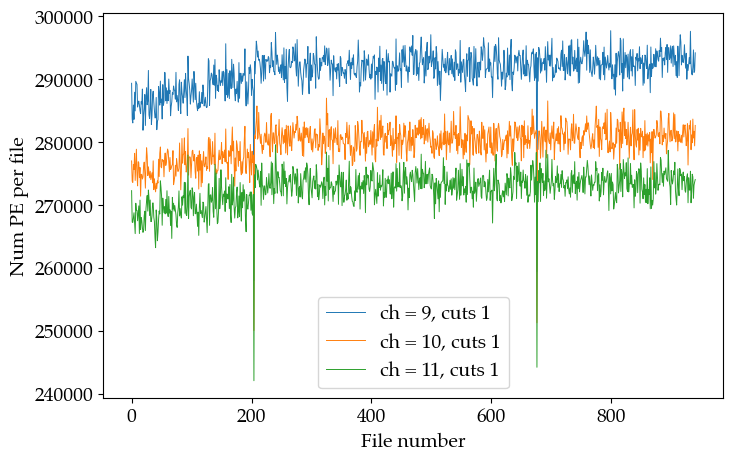

In [242]:
for sel_chs in [[0, 1, 2], [3, 4, 5], [6, 7, 8], [9, 10, 11]]:
    for ch,col in zip(sel_chs, plt.rcParams['axes.prop_cycle'].by_key()['color']):
        plt.plot(num_PEs_chs['num_PEs_0'][ch], label=f'ch = {ch}, cuts 1', color=col, lw=0.7)
        #plt.plot(num_PEs_chs['num_PEs_2'][ch], label=f'ch = {ch}, cuts 2', color=col, ls='--')
    plt.xlabel('File number')
    plt.ylabel('Num PE per file')
    plt.legend()
    plt.show()

## Reject events where the trigger SiPMs have seen only 1PE each (to check if we can change the trigger condition)

In [219]:
all_chs = range(13)

all_params = ['idx_max_cuts3',
              'height_sg_cuts3']

data_lists = {param: {} for param in all_params}
start_time = time.time()

for ifile, sipm_file in enumerate(sorted_files):
    
    if ifile % 20 == 0:
        print(f"Processing file {ifile}/{len(sorted_files)}, {time.time() - start_time}")

    result = process_file(sipm_file, trigg_cut=True)
    if result is None:
        continue

    date, fnum = extract_date_and_number(sipm_file)

    if date not in data_lists[all_params[0]]:
        for ch in all_chs:
            for param in all_params:
                data_lists[param].setdefault(date, {})[ch] = []
                
    for ch in all_chs:
        try:
            if is_non_empty(result[0][ch]):  # not empty
                data_lists['idx_max_cuts3'][date][ch].append(np.concatenate(result[0][ch]))
            
            if ch != 12:
                if is_non_empty(result[2][ch]):
                    data_lists['height_sg_cuts3'][date][ch].append(np.concatenate(result[2][ch]))

        except Exception as e:
            print(f"Error: {date}, {fnum}, {sipm_file}, Ch {ch}: {e}")
            continue
            
final_results = {param: {} for param in all_params}

for key, data in data_lists.items():
    for date, ch_data in data.items():
        final_results[key].setdefault(date, {})
        for ch, array_list in ch_data.items():
            try:
                final_results[key][date][ch] = np.array(np.concatenate(array_list), dtype=int)
            except ValueError:
                continue
            
idx_max_cuts3   = final_results['idx_max_cuts3']
height_sg_cuts3 = final_results['height_sg_cuts3']

end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} s, {elapsed_time/60} min")

Processing file 0/941, 0.0001780986785888672
Processing file 20/941, 12.810106039047241
Processing file 40/941, 25.562204122543335
Processing file 60/941, 37.83331608772278
Processing file 80/941, 50.06785607337952
Processing file 100/941, 62.347453117370605
Processing file 120/941, 74.59301400184631
Processing file 140/941, 86.95022511482239
Processing file 160/941, 99.28726696968079
Processing file 180/941, 111.68919324874878
Processing file 200/941, 124.13598108291626
Processing file 220/941, 136.55975008010864
Processing file 240/941, 148.9956362247467
Processing file 260/941, 161.39169311523438
Processing file 280/941, 173.9740650653839
Processing file 300/941, 186.4665162563324
Processing file 320/941, 198.82630014419556
Processing file 340/941, 211.28874802589417
Processing file 360/941, 223.68349409103394
Processing file 380/941, 236.08022117614746
Processing file 400/941, 248.57771015167236
Processing file 420/941, 261.0366871356964
Processing file 440/941, 273.59930515289307


0
1
2
3
4
5
6
7
8
9
10
11


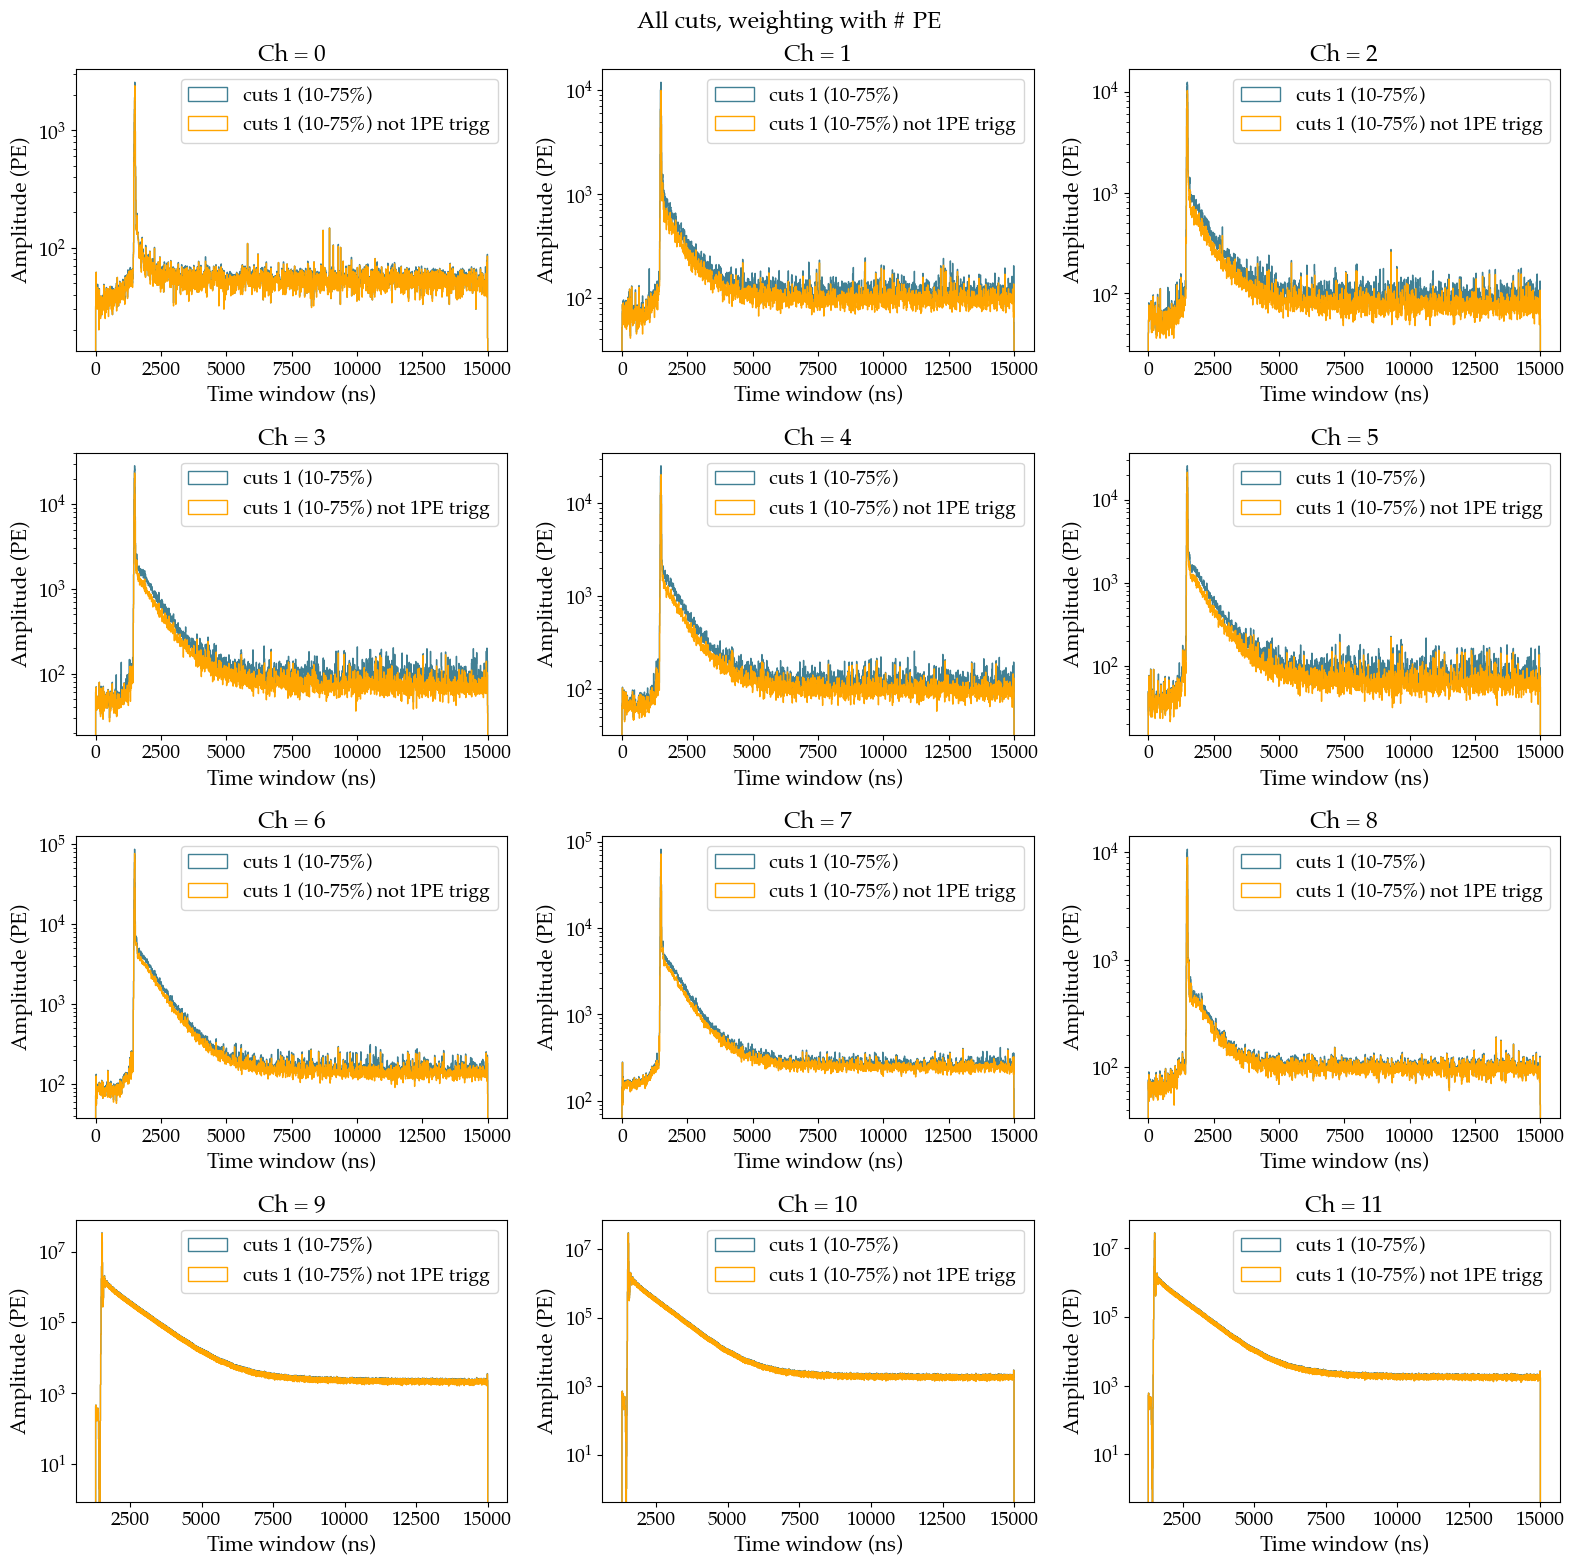

In [221]:
sel_dates = list(idx_max_cuts1.keys())
fig, axs = plt.subplots(4, 3, figsize=(16, 16))
for ch in range(12):
    i = int(ch/3)
    j = ch%3
    print(ch)
    try:
        vals1 = np.concatenate([2*idx_max_cuts1[date][ch] for date in sel_dates])
        h1    = np.concatenate([height_sg_cuts1[date][ch] for date in sel_dates])
        vals3 = np.concatenate([2*idx_max_cuts3[date][ch] for date in sel_dates])
        h3    = np.concatenate([height_sg_cuts3[date][ch] for date in sel_dates])
    
        axs[i][j].hist(vals1, weights=h1, bins=1875, histtype='step', label='cuts 1 (10-75%)', color=fav_col)
        axs[i][j].hist(vals3, weights=h3, bins=1875, histtype='step', label='cuts 1 (10-75%) not 1PE trigg', color='orange')
        axs[i][j].set_title(f'Ch = {ch}')
        axs[i][j].set_xlabel('Time window (ns)', fontsize=15)
        axs[i][j].set_ylabel('Amplitude (PE)',  fontsize=15)
        axs[i][j].set_yscale('log')
        axs[i][j].legend()
    except (KeyError, ValueError):
        continue
plt.suptitle('All cuts, weighting with # PE')
plt.tight_layout()
plt.show()